# Analyse exploratoire des données écologiques

## Objectif

Cette étude explore les sites suivis, l’activité des chauves-souris
et les conditions environnementales.

Nous commençons par décrire les sites, puis nous étudierons
l’évolution des observations au cours du temps.

Les données utilisées proviennent du nettoyage réalisé précédemment.

## Méthodologie et questions d’analyse

### Démarche générale

Nous cherchons à comprendre les variations de l’activité observée
des chauves-souris et leurs relations avec les conditions de suivi,
l’environnement et les événements enregistrés sur les sites.

La démarche est exploratoire. Nous commençons par décrire les données,
puis formulons des questions à partir des résultats obtenus.
Les observations inattendues sont confrontées à plusieurs explications
possibles avant d’être interprétées.

### 1. Comprendre les données et les sites

**Questions :**
- Quels sites sont suivis et dans quels environnements ?
- Les régions présentent-elles les mêmes types de sites ?
- Quels sites peuvent servir de comparateurs ?

**Méthodes :**
Nous utilisons le dictionnaire et les données nettoyées.
Nous décrivons les effectifs par région, type de suivi et habitat,
puis constituons des groupes partageant ces caractéristiques.

### 2. Décrire les variations temporelles

**Questions :**
- Les sites sont-ils suivis sur les mêmes périodes ?
- Les durées d’observation sont-elles comparables ?
- Existe-t-il une saisonnalité ?
- Quels sites présentent les variations les plus importantes ?

**Méthodes :**
Nous examinons la couverture temporelle et calculons les observations
par heure. Nous traçons les évolutions globales, régionales
et individuelles, puis comparons les mois de l’année.

L’amplitude entre les quantiles à 10 % et à 90 % permet de sélectionner
des sites pour une première exploration détaillée, sans qualifier
automatiquement leurs variations d’anormales.

### 3. Examiner les conditions de mesure

**Questions :**
- Les baisses d’activité coïncident-elles avec une dégradation
  de la disponibilité ou de la qualité acoustique ?
- Les périodes avec panne déclarée présentent-elles une activité différente ?
- Les indicateurs techniques diffèrent-ils selon les prestataires ?

**Méthodes :**
Nous rapprochons les relevés et le fonctionnement des appareils
par site et mois. Nous utilisons des graphiques et des corrélations
de Spearman par site, puis comparons les périodes avec panne
à une référence saisonnière locale.

Les prestataires sont comparés avec une valeur par site.
L’absence de changement de prestataire limite la distinction
entre leurs effets et ceux des sites.

### 4. Examiner les conditions environnementales

**Questions :**
- L’activité est-elle associée à la météo, à la végétation,
  aux pesticides ou à la perturbation de l’habitat ?
- Ces associations diffèrent-elles selon les sites ?
- Persistent-elles au-delà du profil saisonnier moyen ?

**Méthodes :**
Nous calculons les corrélations de Spearman séparément par site.
Nous comparons les résultats bruts à ceux obtenus après soustraction
du profil mensuel moyen de chaque variable.

Les cartes de corrélations et les nuages de points permettent
d’examiner les différences et la dispersion des observations.

### 5. Étudier les relations avec les vergers

**Questions :**
- L’activité des chauves-souris est-elle associée à la fructification
  et au rendement ?
- La tendance globale se retrouve-t-elle au sein des vergers ?
- Dépend-elle des taux dont l’échelle est incertaine ou de la saisonnalité ?
- Quelles associations observe-t-on avec les pratiques agricoles
  et les autres pollinisateurs ?

**Méthodes :**
Nous calculons le rendement par hectare et étudions les relations
séparément pour chaque verger.

Une analyse de sensibilité exclut temporairement les taux suspects,
sans modifier les données principales. Nous examinons également
les écarts au profil saisonnier moyen et les autres facteurs agricoles.

### 6. Étudier les événements d’accès

**Questions :**
- L’activité change-t-elle après un accès effectif ?
- La variation peut-elle être liée à la saisonnalité ?
- Les sites comparables connaissent-ils la même évolution aux mêmes dates ?
- Les résultats diffèrent-ils selon les organisations demandeuses ?
- Le contraste dépend-il des accès répétés sur certains sites ?

**Méthodes :**
Nous comparons trois mois avant et trois mois après chaque accès
disposant d’une fenêtre complète, en excluant le mois de l’intervention.

Nous utilisons ensuite une référence saisonnière locale et des sites
comparables sans accès enregistré dans la fenêtre étudiée.

Les résultats sont comparés par organisation, puis résumés par site.
Un graphe biparti représente les liens sites–accès.
Un cas présentant une forte baisse est examiné plus précisément
avec ses conditions techniques et environnementales.

### 7. Analyser et confronter les rapports de terrain

**Questions :**
- Quels sujets et formulations reviennent dans les rapports ?
- Quels documents présentent un contenu distinct ?
- Les références, les sites et les dates concordent-ils avec les tableaux ?
- Les mesures soutiennent-elles les affirmations des textes ?
- Quelles explications alternatives et quelles incertitudes sont mentionnées ?

**Méthodes :**
Nous utilisons les fréquences de mots et de bigrammes, TF-IDF
et la similarité cosinus sur une copie préparée des textes.

Les 30 rapports sont ensuite lus et confrontés aux enquêtes,
aux appareils et aux mesures cités. Les textes originaux sont conservés
pour interpréter les négations et les incertitudes.

### 8. Construire la synthèse

**Questions :**
- Quels résultats concordent entre plusieurs sources ?
- Quelles contradictions limitent leur interprétation ?
- Quelles pistes doivent être croisées avec les autres domaines du projet ?

**Méthodes :**
Nous distinguons les mesures, les affirmations documentaires
et les hypothèses. Les contre-exemples et les informations manquantes
sont conservés dans le bilan.

Les comparaisons restent exploratoires : les facteurs de confusion
ne sont pas tous contrôlés simultanément et les résultats
ne démontrent pas de causalité.

Les fonctions réutilisables sont regroupées dans `eco_utils.py`.
Le notebook présente les méthodes, les résultats
et leurs limites.

### Utilisation de l’intelligence artificielle

Une IA générative a été utilisée pour aider à la syntaxe Python,
au débogage du code, à l’explication et à la proposition d’algorithmes,
à la formulation des interprétations et à la rédaction
de la documentation.

In [1]:
from pathlib import Path
import sys
import importlib

import pandas as pd
import matplotlib.pyplot as plt

# Définir la racine du projet
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Ajouter src au chemin des modules Python
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Importer les fonctions utilitaires
import eco_utils
importlib.reload(eco_utils)

<module 'eco_utils' from 'C:\\Users\\Lenovo\\Desktop\\Data Mining\\20262027-UE-DataMining-Project\\src\\eco_utils.py'>

## 1. Description des sites

Le fichier `monitoring_sites.csv` décrit les sites du programme
de suivi écologique. Chaque site est identifié par `site_code`.

Nous examinons leur nombre, leur localisation et leur type de milieu.

In [2]:
data_path = PROJECT_ROOT / "data" / "ecology_cleaned"

sites = pd.read_csv(data_path / "monitoring_sites.csv")

print("Nombre de sites :", len(sites))
print("Nombre de colonnes :", sites.shape[1])

display(sites.head())

Nombre de sites : 64
Nombre de colonnes : 13


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,active


### 1.1. Répartition des sites

Nous décrivons les sites selon leur région, leur type de suivi
et leur habitat.

Les effectifs et les pourcentages permettent de vérifier
si certaines catégories sont davantage représentées.

In [3]:

for column in ["region", "site_category", "habitat_category"]:
    print(f"\nRépartition selon : {column}")
    display(eco_utils.summarize_categories(sites, column))


Répartition selon : region


,effectif,pourcentage
region,,
Kintara Karst Cluster,22,34.38
Eastern Avelora Agricultural Cluster,22,34.38
Tembara Coastal Cluster,20,31.25



Répartition selon : site_category


,effectif,pourcentage
site_category,,
habitat monitoring,40,62.5
orchard monitoring,16,25.0
cave monitoring,8,12.5



Répartition selon : habitat_category


,effectif,pourcentage
habitat_category,,
mixed_forest,19,29.69
durian_orchard,10,15.62
coastal_habitat,10,15.62
karst_habitat,9,14.06
research_site,6,9.38
mixed_agriculture,5,7.81
protected_forest,3,4.69
degraded_land,2,3.12


### Interprétation

Les 64 sites sont répartis de manière assez équilibrée entre
les trois régions : 22 à Kintara, 22 dans l’est d’Avelora
et 20 à Tembara.

Les types de suivi sont moins équilibrés. Le suivi des habitats
représente 62,5 % des sites, contre 25 % pour les vergers
et 12,5 % pour les grottes.

Les forêts mixtes constituent l’habitat le plus représenté
avec 19 sites. Les autres habitats comptent entre 2 et 10 sites.

Ces différences d’effectifs devront être prises en compte
dans les comparaisons : un total plus élevé peut simplement
refléter un plus grand nombre de sites suivis.

### 1.2. Types de sites par région

Nous croisons la région et le type de suivi pour examiner
la composition des trois groupes régionaux.

Des différences de composition pourraient contribuer
aux écarts observés ensuite entre les régions.

In [4]:
sites_by_region = pd.crosstab(
    sites["region"],
    sites["site_category"]
)

display(sites_by_region)

site_category,cave monitoring,habitat monitoring,orchard monitoring
region,,,
Eastern Avelora Agricultural Cluster,0,9,13
Kintara Karst Cluster,7,15,0
Tembara Coastal Cluster,1,16,3


### Interprétation

L’est d’Avelora concentre 13 des 16 sites de suivi des vergers.
Kintara rassemble 7 des 8 sites de suivi des grottes.
À Tembara, le suivi des habitats prédomine avec 16 sites sur 20.

Les comparaisons régionales devront tenir compte de ces différences.
Un écart d’activité entre régions pourrait être associé au type
de sites suivis, et pas uniquement à leur localisation.

### 1.3. Répartition visuelle des sites

Le premier graphique présente les effectifs par habitat.
Le second montre la composition des régions selon le type de suivi.

Ces représentations permettent de repérer les catégories
dominantes et les différences de composition entre régions.

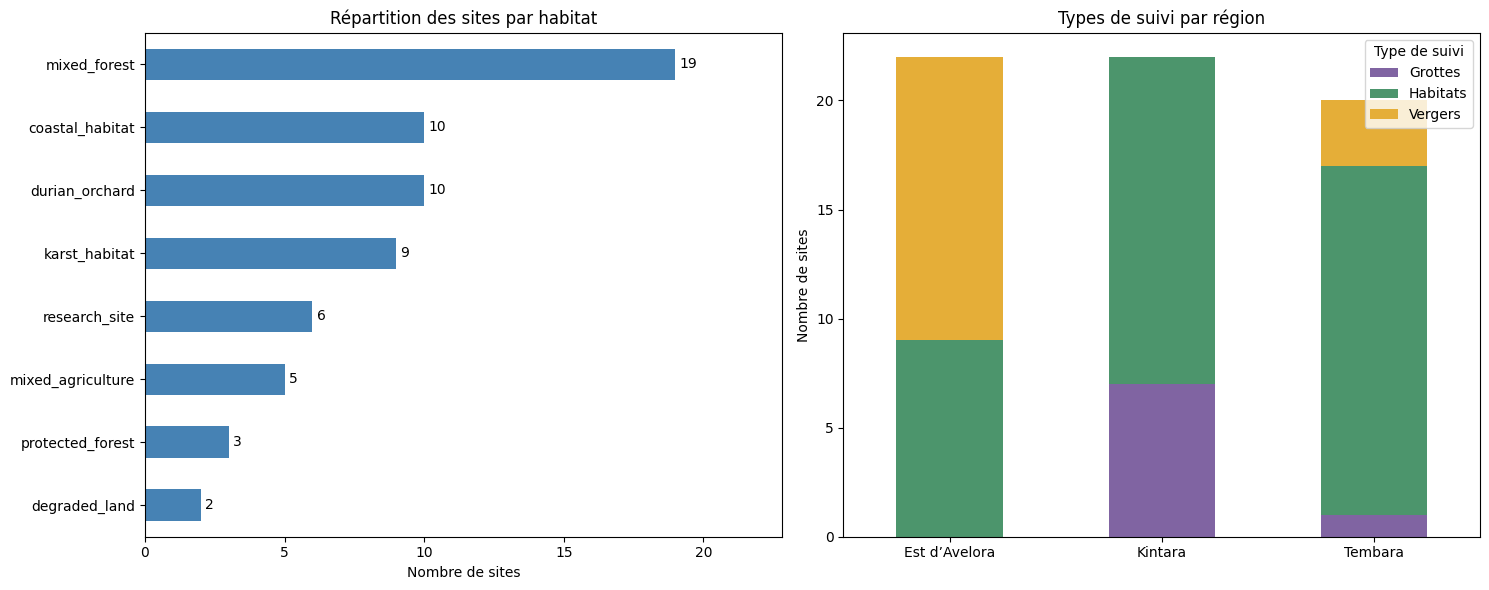

In [5]:
eco_utils.plot_site_distributions(sites)

### Lecture des graphiques

Les forêts mixtes sont l’habitat le plus représenté, avec 19 sites.
Les autres habitats comptent entre 2 et 10 sites.

La composition des régions diffère : l’est d’Avelora concentre
les suivis de vergers, tandis que Kintara rassemble la majorité
des suivis de grottes. À Tembara, le suivi des habitats domine.

Ces différences devront être prises en compte pour comparer
l’activité des chauves-souris entre régions.

### 1.4. Constitution de groupes de sites comparables

Nous regroupons les sites selon trois caractéristiques :
la région, le type de suivi et l’habitat.

Cette première classification permet d’identifier des sites
partageant un contexte similaire. Elle ne garantit pas des
conditions identiques : la météo, l’effort d’observation et
le fonctionnement des appareils devront aussi être considérés.

Les groupes ne contenant qu’un site ne permettront pas
de comparaison interne.

In [6]:

site_groups = eco_utils.summarize_comparable_site_groups(sites)

display(site_groups)

,region,site_category,habitat_category,nombre_sites,sites
0,Tembara Coastal Cluster,habitat monitoring,coastal_habitat,9,"TMB-AYQ, TMB-CKU, TMB-DLQ, TMB-GWP, TMB-PEL, T..."
1,Kintara Karst Cluster,habitat monitoring,mixed_forest,8,"KNT-DMJ, KNT-GKR, KNT-TEX, KNT-TLQ, KNT-UJJ, K..."
2,Kintara Karst Cluster,cave monitoring,karst_habitat,7,"KNT-BME, KNT-CYP, KNT-JAK, KNT-KES, KNT-LUM, K..."
3,Tembara Coastal Cluster,habitat monitoring,mixed_forest,7,"TMB-GZX, TMB-HFR, TMB-HVD, TMB-QCB, TMB-UVF, T..."
4,Eastern Avelora Agricultural Cluster,orchard monitoring,durian_orchard,7,"AVL-ECJ, AVL-KAR, AVL-MAR, AVL-NMQ, AVL-RBC, A..."
5,Eastern Avelora Agricultural Cluster,orchard monitoring,mixed_agriculture,5,"AVL-FNQ, AVL-GRB, AVL-HUA, AVL-NFR, AVL-TRP"
6,Eastern Avelora Agricultural Cluster,habitat monitoring,research_site,5,"AVL-ARU, AVL-BVM, AVL-FNM, AVL-HTY, AVL-RNY"
7,Eastern Avelora Agricultural Cluster,habitat monitoring,mixed_forest,4,"AVL-ABG, AVL-BWK, AVL-DER, AVL-SEY"
8,Tembara Coastal Cluster,orchard monitoring,durian_orchard,3,"TMB-BRC, TMB-HQL, TMB-SKZ"
9,Kintara Karst Cluster,habitat monitoring,protected_forest,3,"KNT-JQG, KNT-WUQ, KNT-XAC"


### Bilan des groupes de sites

Le croisement de la région, du type de suivi et de l’habitat
définit 14 groupes, dont les effectifs vont de 1 à 9 sites.

Douze groupes rassemblent plusieurs sites, soit 62 sites au total.
Ils constituent une première base pour comparer des sites
partageant un contexte similaire.

AVL-ORR et TMB-NAC sont seuls dans leur groupe. Ils ne disposent
donc pas de comparateur réunissant exactement les trois critères.

Cette classification repose sur les caractéristiques des sites,
sans utiliser leurs résultats d’activité. Elle ne garantit pas
des conditions identiques et ne constitue pas un clustering
fondé sur les mesures.

## 2. Évolution de l’activité des chauves-souris

### 2.1. Période et couverture des relevés

Avant de tracer les séries temporelles, nous vérifions la période
couverte et le nombre de relevés disponibles pour chaque site.

Ce contrôle permet de repérer d’éventuelles différences de suivi
qui pourraient influencer les comparaisons.

In [7]:

bats = pd.read_csv(
    data_path / "bat_surveys.csv",
    parse_dates=["survey_start", "survey_end"]
)

print("Nombre de relevés :", len(bats))
print("Nombre de sites :", bats["site_code"].nunique())
print("Premier relevé :", bats["survey_start"].min())
print("Dernier relevé :", bats["survey_start"].max())

coverage = eco_utils.summarize_survey_coverage(bats)

display(coverage)

print("\nRépartition du nombre de mois suivis :")
display(coverage["nombre_mois"].value_counts().sort_index())

Nombre de relevés : 4992
Nombre de sites : 64
Premier relevé : 2019-01-05 18:00:00
Dernier relevé : 2025-06-05 18:00:00


,nombre_releves,nombre_mois,premier_releve,dernier_releve
site_code,,,,
AVL-ABG,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
AVL-ARU,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
AVL-BVM,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
AVL-BWK,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
AVL-DER,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
...,...,...,...,...
TMB-VZT,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
TMB-WQL,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00
TMB-WST,78,78,2019-01-05 18:00:00,2025-06-05 18:00:00



Répartition du nombre de mois suivis :


nombre_mois
78    64
Name: count, dtype: int64

### Interprétation

Les données comprennent 4 992 relevés répartis sur 64 sites.
Chaque site possède un relevé mensuel de janvier 2019 à juin 2025,
soit 78 mois, sans mois manquant sur cette période.

La couverture temporelle est identique entre les sites.
Cependant, les heures d’observation et la disponibilité des capteurs
peuvent varier et devront être prises en compte.

L’année 2025 ne couvre que janvier à juin : ses totaux ne seront
pas directement comparés à ceux des années complètes.

### 2.2. Effort d’observation

Le nombre de chauves-souris observées peut dépendre du temps
consacré au suivi. Nous examinons les heures d’observation
avant de comparer les comptages entre sites et périodes.

In [8]:
display(bats["observation_hours"].describe())

print(
    "Durées absentes ou non positives :",
    (
        bats["observation_hours"].isna()
        | bats["observation_hours"].le(0)
    ).sum()
)

count    4992.000000
mean       30.327524
std         5.504168
min         5.000000
25%        26.900000
50%        30.600000
75%        34.100000
max        46.900000
Name: observation_hours, dtype: float64

Durées absentes ou non positives : 0


### Interprétation

La durée médiane d’observation est de 30,6 heures par relevé,
mais les durées varient entre 5 et 46,9 heures.

Nous calculons donc le nombre de chauves-souris observées par heure
pour tenir compte des différences d’effort.

Cet indicateur représente une activité observée. Il ne mesure pas
directement la taille des populations et ne corrige pas les effets
de la météo, de la méthode de suivi ou des capteurs.

In [9]:

bats = eco_utils.add_bat_observation_rate(bats)

display(
    bats[
        [
            "site_code",
            "survey_start",
            "observed_bat_count",
            "observation_hours",
            "bats_per_hour"
        ]
    ].head()
)

display(bats["bats_per_hour"].describe())

,site_code,survey_start,observed_bat_count,observation_hours,bats_per_hour
0,KNT-KES,2019-01-05 18:00:00,7,28.6,0.244755
1,KNT-KES,2019-02-05 18:00:00,8,31.7,0.252366
2,KNT-KES,2019-03-05 18:00:00,22,32.4,0.679012
3,KNT-KES,2019-04-05 18:00:00,26,35.7,0.728291
4,KNT-KES,2019-05-05 18:00:00,23,32.0,0.718750


count    4992.000000
mean        0.466249
std         0.259228
min         0.000000
25%         0.290323
50%         0.424837
75%         0.596026
max         2.417219
Name: bats_per_hour, dtype: float64

### 2.3. Évolution mensuelle de l’activité observée

Pour chaque mois, nous calculons la médiane des observations
par heure sur les 64 sites.

La zone entre le premier et le troisième quartile représente
la dispersion entre les sites : elle contient les 50 % de valeurs
centrales. Il ne s’agit pas d’un intervalle de confiance.

Cette vue d’ensemble permet de repérer des variations communes.
Elle sera ensuite complétée par des comparaisons entre sites.

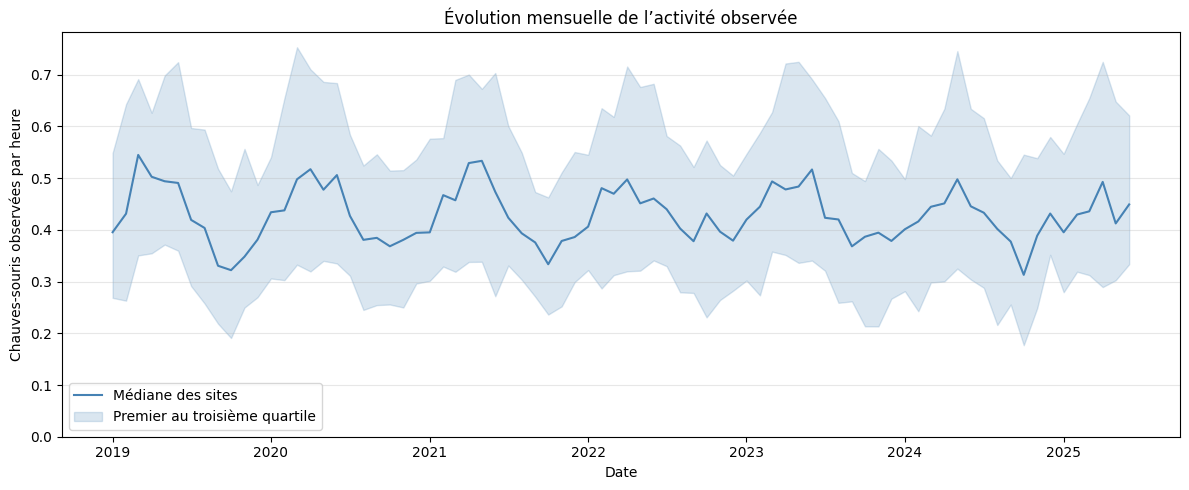

In [10]:

monthly_activity = eco_utils.plot_monthly_bat_activity(bats)

### Première lecture

La médiane de l’activité observée varie régulièrement au cours
du temps. La répétition de hausses et de baisses d’une année
à l’autre suggère une composante saisonnière.

Aucune tendance durable ne ressort clairement de cette vue
d’ensemble. La dispersion entre les sites reste importante :
la médiane peut masquer des évolutions locales différentes.

Nous examinons maintenant les résultats par mois de l’année
pour préciser le profil saisonnier.

### 2.4. Profil saisonnier

Pour chaque mois de l’année, nous comparons les médianes
mensuelles obtenues sur les différentes années.

Chaque boîte résume six ou sept valeurs annuelles.
Janvier à juin comprennent également les observations de 2025,
tandis que juillet à décembre s’arrêtent en 2024.

Cette comparaison décrit une saisonnalité possible sans
en déterminer les causes.

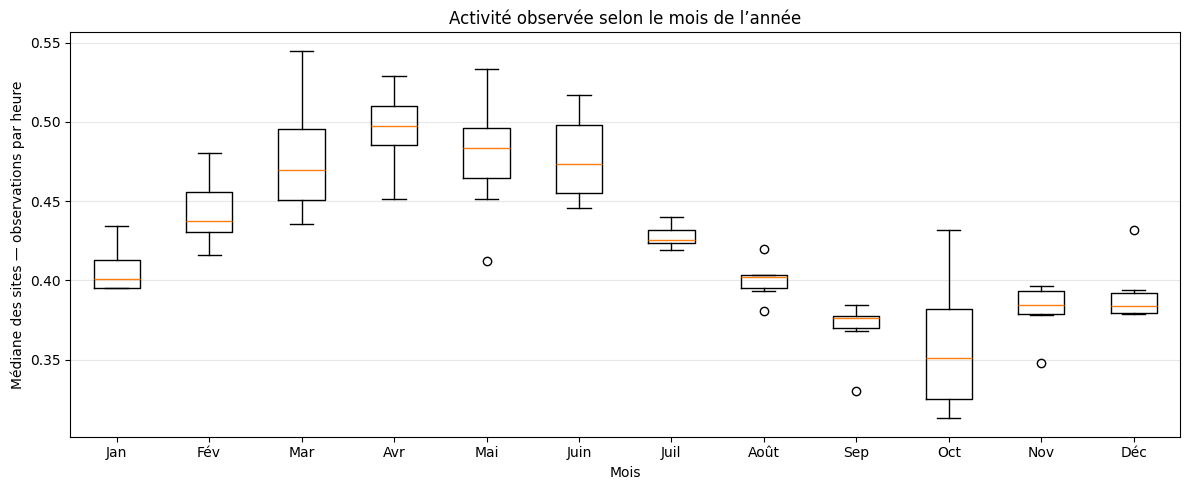

In [11]:

eco_utils.plot_bat_seasonality(monthly_activity)

### Interprétation du profil saisonnier

L’activité observée présente un profil saisonnier : elle augmente
entre janvier et avril, reste relativement élevée en mai et juin,
puis diminue jusqu’en septembre et octobre.

La médiane est proche de 0,50 observation par heure en avril,
contre environ 0,35 en octobre. Ces valeurs décrivent le profil
global des sites et peuvent masquer des différences locales.

Les points situés hors des moustaches signalent des valeurs
atypiques parmi les années comparées. Ils ne constituent pas
automatiquement des erreurs ou des événements anormaux.

Pour rechercher une baisse inhabituelle, il faudra donc comparer
des périodes équivalentes et tenir compte de cette saisonnalité.

### 2.5. Comparaison des évolutions régionales

Nous calculons la médiane mensuelle des observations par heure
dans chaque région pour comparer leurs évolutions.

Cette comparaison reste descriptive : les régions ne présentent
pas les mêmes proportions de grottes, de vergers et d’habitats.
Les écarts ne peuvent donc pas être attribués à la seule région.

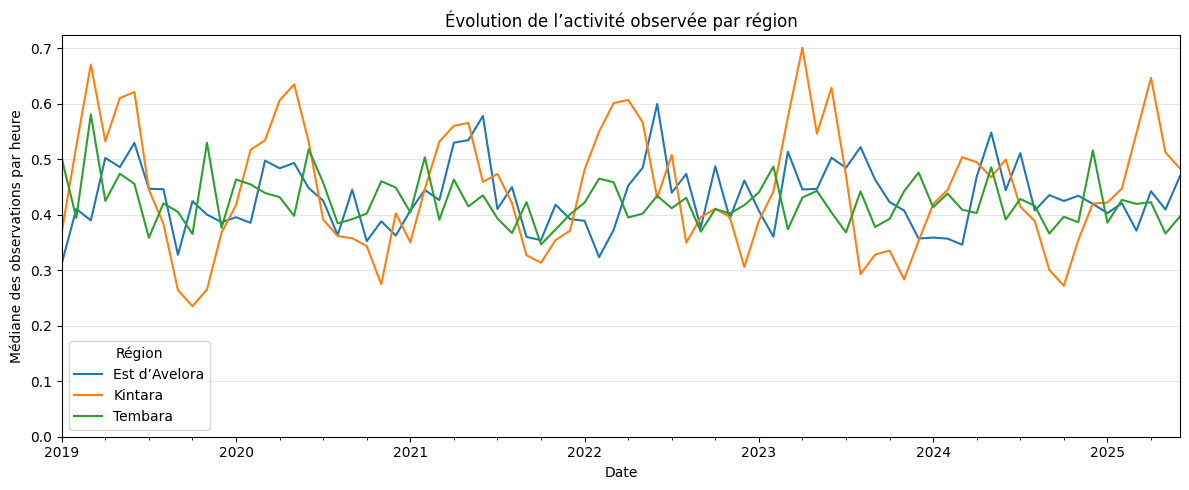

In [12]:

regional_activity = eco_utils.plot_bat_activity_by_region(bats, sites)

### Interprétation des évolutions régionales

Les trois régions présentent des variations au cours du temps,
mais leur amplitude diffère.

Kintara montre les oscillations les plus marquées. Tembara
présente une évolution visuellement plus stable, tandis que
l’est d’Avelora connaît plusieurs pics ponctuels.

Ces courbes ne permettent pas d’attribuer les différences
à une cause particulière. Les types de sites, les conditions
environnementales et les modalités de suivi peuvent intervenir.

Les médianes régionales peuvent également masquer des variations
propres à certains sites. Nous examinons donc les sites séparément.

### 2.6. Variations de l’activité selon les sites

Pour chaque site, nous calculons la médiane et les quantiles
à 10 % et à 90 % des observations par heure.

L’écart entre ces deux quantiles décrit l’amplitude des variations
en limitant l’influence des valeurs les plus extrêmes.

Nous examinons d’abord les sites présentant les amplitudes
les plus élevées. Une forte variation peut refléter la saisonnalité
ou d’autres facteurs et ne constitue pas, à elle seule, une anomalie.

In [13]:

site_activity = eco_utils.summarize_bat_activity_by_site(bats, sites)

display(site_activity.head(10).round(3))

,site_code,mediane,q10,q90,amplitude_centrale,region,site_category
0,TMB-BRC,1.354,0.982,1.764,0.781,Tembara Coastal Cluster,orchard monitoring
1,KNT-KES,0.538,0.241,0.916,0.675,Kintara Karst Cluster,cave monitoring
2,KNT-VLB,0.511,0.221,0.868,0.647,Kintara Karst Cluster,habitat monitoring
3,KNT-CHP,0.714,0.426,1.071,0.645,Kintara Karst Cluster,habitat monitoring
4,AVL-VEL,0.624,0.342,0.957,0.616,Eastern Avelora Agricultural Cluster,orchard monitoring
5,KNT-CYP,0.819,0.567,1.166,0.599,Kintara Karst Cluster,cave monitoring
6,AVL-RBC,0.675,0.412,1.003,0.591,Eastern Avelora Agricultural Cluster,orchard monitoring
7,AVL-YAU,0.784,0.498,1.079,0.581,Eastern Avelora Agricultural Cluster,orchard monitoring
8,AVL-NMQ,0.732,0.533,1.105,0.573,Eastern Avelora Agricultural Cluster,orchard monitoring
9,TMB-NAC,0.597,0.318,0.887,0.570,Tembara Coastal Cluster,cave monitoring


### Interprétation

TMB-BRC présente la plus grande amplitude centrale, avec environ
0,78 observation par heure entre les quantiles à 10 % et à 90 %.
Son activité médiane est également élevée, à environ 1,35.

KNT-KES et KNT-VLB présentent ensuite les amplitudes les plus fortes,
avec des niveaux médians plus faibles.

Ce classement décrit des variations absolues. Il ne permet pas
de distinguer une saisonnalité régulière d’une rupture ponctuelle.
Nous examinons les courbes des trois premiers sites pour préciser
la forme de ces variations.

### 2.7. Évolution des sites présentant les plus fortes variations

Nous représentons les trois sites en tête du classement.
Les graphiques utilisent la même échelle verticale pour faciliter
la comparaison des niveaux et des amplitudes.

Nous cherchons à distinguer les oscillations régulières,
les pics isolés et les éventuelles baisses prolongées.
Les causes seront examinées dans un second temps.

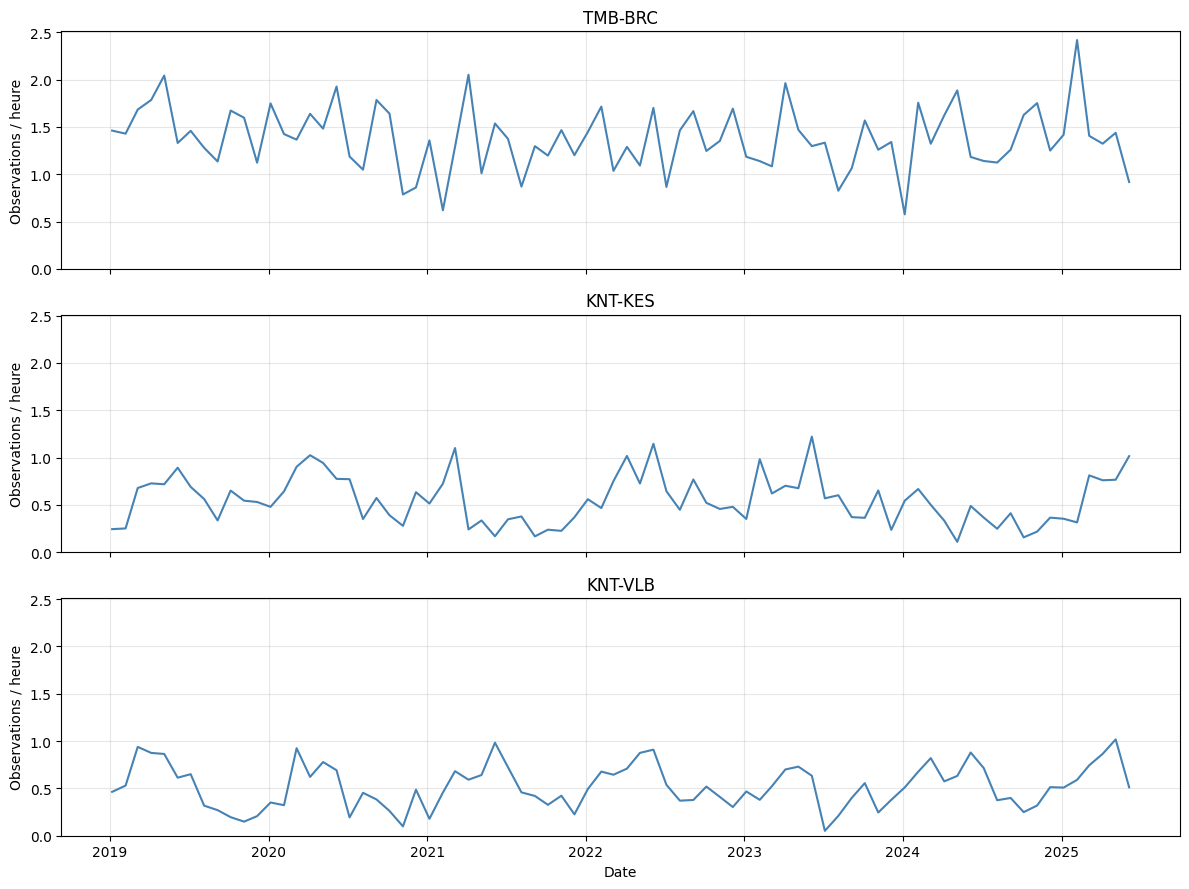

In [14]:

selected_sites = site_activity.head(3)["site_code"].tolist()

eco_utils.plot_selected_site_activity(bats, selected_sites)

### Interprétation des courbes individuelles

TMB-BRC présente une activité globalement plus élevée que les deux
autres sites, avec des fluctuations importantes.

KNT-KES montre plusieurs périodes de faible activité, notamment
en 2021 et en 2024, suivies de remontées. KNT-VLB présente
des oscillations récurrentes et quelques creux ponctuels.

Ces courbes montrent que des amplitudes importantes peuvent
correspondre à des comportements différents. Elles ne permettent
pas encore de distinguer saisonnalité, variation écologique
et problème de mesure.

Nous examinons maintenant le fonctionnement des appareils
pour vérifier si certaines baisses coïncident avec une dégradation
du suivi.

### Bilan de l’évolution temporelle

Les données comprennent 4 992 relevés, soit un relevé mensuel
pour chacun des 64 sites entre janvier 2019 et juin 2025.

Les durées d’observation varient de 5 à 46,9 heures.
Nous utilisons donc les observations par heure pour tenir compte
de cette différence d’effort.

L’activité globale présente un profil saisonnier, avec des niveaux
généralement plus élevés au printemps et plus faibles vers
septembre et octobre. Aucune tendance durable ne ressort
clairement de la médiane globale.

Les évolutions locales sont différentes. TMB-BRC présente
une activité élevée et fluctuante. KNT-KES montre plusieurs
périodes de faible activité, notamment en 2021 et en 2024.
KNT-VLB présente des oscillations récurrentes.

Ces variations ne constituent pas automatiquement des anomalies.
Elles doivent être examinées en tenant compte de la saisonnalité
et des conditions de suivi. L’année 2025 étant incomplète,
ses totaux ne sont pas directement comparables aux années entières.

## 3. Fiabilité du suivi

### 3.1. Rapprochement avec le fonctionnement des appareils

Nous associons chaque relevé aux informations de fonctionnement
du même site et du même mois.

Nous conservons tous les relevés et vérifions la présence
d’une correspondance avant d’interpréter la disponibilité,
la qualité acoustique et les pannes déclarées.

In [15]:

operations = pd.read_csv(
    data_path / "monitoring_device_operations.csv",
    parse_dates=["operation_start", "operation_end"]
)

bats_devices = eco_utils.link_surveys_to_devices(bats, operations)

print("Nombre de relevés après jointure :", len(bats_devices))
print("\nCorrespondances avec les appareils :")
display(bats_devices["device_match"].value_counts())

Nombre de relevés après jointure : 4992

Correspondances avec les appareils :


device_match
both          4992
left_only        0
right_only       0
Name: count, dtype: int64

### 3.2. Activité observée et fonctionnement des appareils

Pour les trois sites examinés, nous comparons l’évolution
des observations par heure avec la disponibilité des appareils
et leur score de qualité acoustique.

Nous recherchons des baisses simultanées qui pourraient signaler
une influence des conditions de mesure.

La disponibilité est un pourcentage et la qualité acoustique
est un score distinct. Leurs valeurs ne sont pas directement
équivalentes. Une concordance visuelle devra être vérifiée
avant toute conclusion.

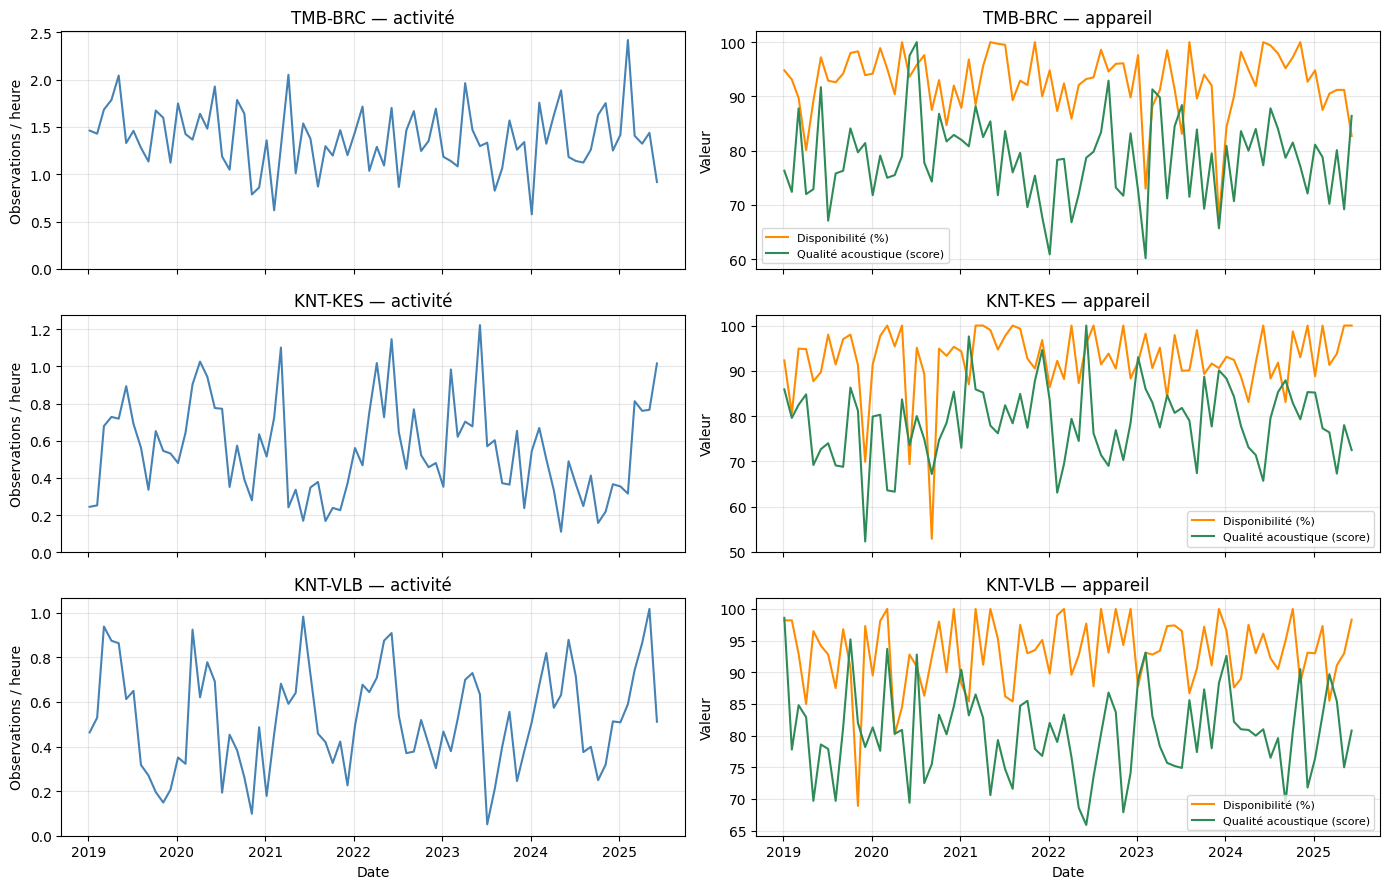

In [16]:
eco_utils.plot_activity_and_device_quality(
    bats_devices,
    selected_sites
)

### Première interprétation

La disponibilité des appareils reste généralement élevée,
tandis que la qualité acoustique fluctue davantage.

Les variations de l’activité observée ne suivent pas systématiquement
celles des indicateurs techniques. À KNT-KES, certaines périodes
de faible activité ne s’accompagnent pas d’une chute comparable
de la disponibilité.

Les conditions techniques pourraient contribuer à certaines variations,
mais les graphiques ne permettent pas de leur attribuer toutes les baisses.
Nous complétons cette lecture par des corrélations calculées par site.

### 3.3. Association avec les indicateurs techniques

Nous calculons, pour chaque site sélectionné, la corrélation
de Spearman entre l’activité observée et les deux indicateurs
de fonctionnement.

Une corrélation positive indique que les valeurs tendent à augmenter
ensemble. Une valeur proche de zéro indique une faible association
monotone sur l’ensemble de la période.

Ces corrélations restent descriptives : elles ne contrôlent pas
la saisonnalité et ne permettent ni de démontrer une cause
ni d’exclure un problème technique ponctuel.

In [17]:
importlib.reload(eco_utils)

device_correlations = eco_utils.summarize_device_correlations(
    bats_devices,
    selected_sites
)

display(device_correlations.round(3))

,site_code,indicateur,nombre_paires,spearman
0,TMB-BRC,uptime_pct,78,-0.002
1,TMB-BRC,acoustic_quality,78,-0.033
2,KNT-KES,uptime_pct,78,0.100
3,KNT-KES,acoustic_quality,78,-0.134
4,KNT-VLB,uptime_pct,78,0.030
5,KNT-VLB,acoustic_quality,78,-0.152


### Interprétation des corrélations

Les corrélations de Spearman sont proches de zéro pour les trois
sites étudiés, avec des valeurs comprises entre −0,152 et 0,100.

L’activité observée ne présente donc pas d’association monotone
marquée avec la disponibilité des appareils ou la qualité acoustique
sur l’ensemble de la période.

Ce résultat ne permet pas d’exclure un problème technique ponctuel,
un effet non linéaire ou une influence combinée avec d’autres facteurs.
Les indicateurs techniques ne constituent pas, à ce stade,
une explication suffisante des variations observées.

Nous examinons ensuite les conditions environnementales.

### 3.4. Associations techniques sur l’ensemble des sites

Nous étendons les corrélations entre activité, disponibilité
et qualité acoustique aux 64 sites.

Chaque coefficient est calculé séparément pour un site.
Les distributions permettent d’examiner si les faibles associations
observées sur les trois premiers sites se retrouvent ailleurs.

Cette analyse reste descriptive et ne permet pas d’exclure
des problèmes techniques ponctuels.

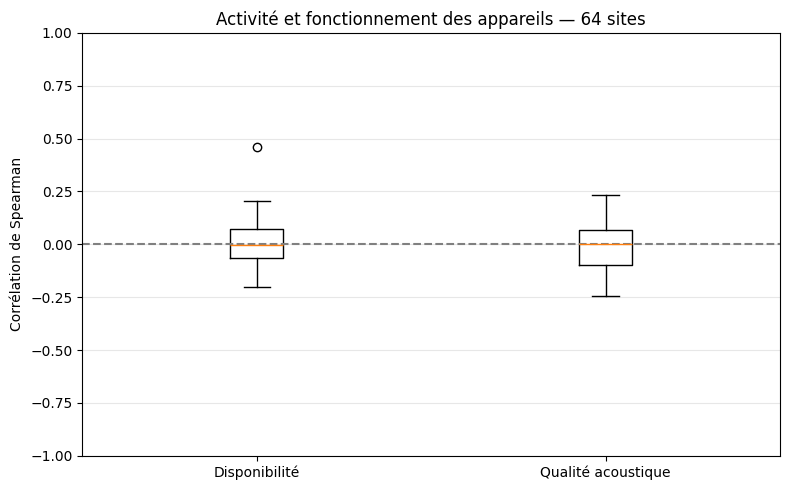

In [18]:

all_device_correlations = eco_utils.correlations_by_site(
    bats_devices,
    bats_devices["site_code"].unique().tolist(),
    ["uptime_pct", "acoustic_quality"]
)

eco_utils.plot_device_correlation_distributions(
    all_device_correlations
)

### Interprétation sur les 64 sites

Les distributions des corrélations avec la disponibilité
et la qualité acoustique sont centrées près de zéro.

À l’échelle des sites, ces indicateurs ne présentent donc pas
d’association monotone commune et marquée avec l’activité observée.

Une corrélation positive plus élevée apparaît pour la disponibilité
sur un site. Les situations individuelles peuvent ainsi différer
du résultat général.

Ces corrélations calculées sur toute la période ne permettent pas
d’exclure une influence technique ponctuelle. Nous examinons
maintenant les périodes comportant une panne déclarée.

### 3.5. Pannes déclarées

Nous décrivons les codes de panne enregistrés avant de comparer
l’activité observée pendant les différentes situations techniques.

L’absence de panne déclarée ne garantit pas l’absence
d’un problème de mesure.

In [19]:
fault_counts = (
    bats_devices["fault_code"]
    .fillna("NON_RENSEIGNE")
    .value_counts()
    .rename_axis("code_panne")
    .to_frame("nombre_releves")
)

display(fault_counts)

,nombre_releves
code_panne,
NO_FAULT,4803
MICROPHONE_DRIFT,97
STORAGE_LIMIT,56
POWER_INTERRUPTION,36


Les données contiennent 189 relevés avec une panne déclarée :
97 dérives de microphone, 56 limitations de stockage
et 36 interruptions d’alimentation.

Les 4 803 autres relevés portent le code NO_FAULT, utilisé
dans le nettoyage pour désigner l’absence de panne déclarée.

Nous comparons chaque relevé avec panne à la médiane des relevés
sans panne déclarée du même site et du même mois de l’année,
sur les autres années disponibles.

Cette référence tient compte du site et du profil saisonnier,
mais pas de toutes les différences météorologiques ou temporelles.

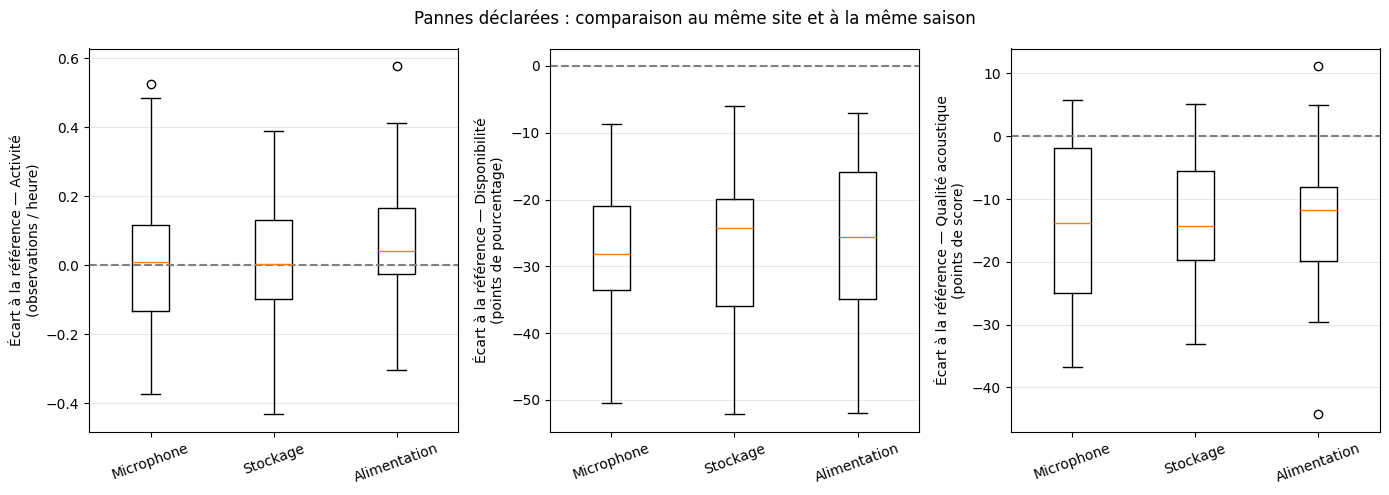

In [20]:

fault_comparison = eco_utils.compare_declared_faults(bats_devices)

### Interprétation des périodes avec panne déclarée

Les relevés avec panne présentent une disponibilité nettement
inférieure à la référence du même site et du même mois de l’année.
Les écarts médians sont visuellement proches de −25 à −30 points
de pourcentage selon le type de panne.

La qualité acoustique est également généralement plus faible,
avec des écarts médians d’environ −12 à −15 points de score.

En revanche, les écarts d’activité sont répartis de part et d’autre
de zéro. Aucune baisse systématique des observations par heure
ne ressort de cette comparaison.

Les pannes déclarées s’accompagnent donc de conditions techniques
dégradées, sans diminution uniforme de l’indicateur d’activité.
Cela ne garantit pas la fiabilité de chaque relevé et ne permet
pas d’exclure un biais ponctuel.

### 3.6. Prestataires de maintenance

Nous décrivons les opérations et les sites associés à chaque
prestataire, puis recherchons d’éventuels changements de prestataire
au sein d’un même site.

Si les prestataires suivent des sites différents, leurs résultats
ne pourront pas être interprétés comme un effet propre
du prestataire : les caractéristiques des sites peuvent intervenir.

Certaines valeurs de prestataire ont été imputées pendant
le nettoyage ; elles restent des attributions supposées.

In [21]:

provider_summary, providers_per_site = (
    eco_utils.summarize_maintenance_providers(operations)
)

display(provider_summary)

print(
    "Sites associés à plusieurs prestataires :",
    providers_per_site.gt(1).sum()
)

,nombre_operations,nombre_sites,nombre_appareils
maintenance_provider,,,
ECO-SERVICE-1,1248,16,16
ECO-SERVICE-2,1248,16,16
ECO-SERVICE-3,1248,16,16
ECO-SERVICE-4,1248,16,16


Sites associés à plusieurs prestataires : 0


### Comparaison des indicateurs par prestataire

Les quatre prestataires suivent chacun 16 sites. Aucun site
ne change de prestataire dans les données préparées.

Nous comparons la disponibilité médiane, la qualité acoustique
médiane et la proportion de relevés avec panne déclarée.
Chaque site contribue par une valeur à chaque distribution.

Ces comparaisons sont descriptives : une différence peut provenir
du prestataire, des appareils ou des conditions propres aux sites.
Les attributions imputées pendant le nettoyage restent également
fondées sur une hypothèse de stabilité.

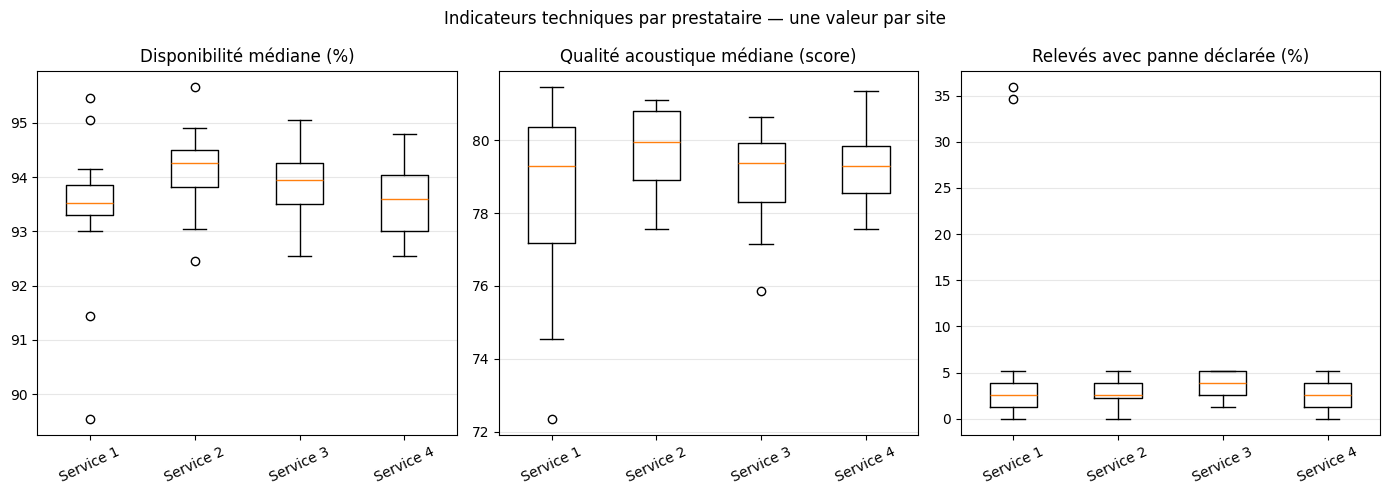

In [22]:
provider_site_summary = eco_utils.plot_maintenance_provider_comparison(
    bats_devices,
    operations
)

### Interprétation de la comparaison des prestataires

Les distributions de disponibilité médiane sont proches :
la plupart des sites présentent des valeurs comprises autour
de 93 à 95 %. Les distributions de qualité acoustique médiane
se recouvrent également largement.

La proportion de relevés avec panne déclarée reste généralement
faible. Deux sites associés au service 1 se distinguent toutefois
avec environ 35 % de relevés concernés.

Ces observations justifient un examen des sites concernés,
sans permettre d’attribuer les différences au prestataire.
Chaque site étant associé à un seul prestataire, leurs effets
ne peuvent pas être séparés par cette comparaison.

In [23]:
display(
    provider_site_summary
    .sort_values("pannes_pct", ascending=False)
    .head(5)
    .round(2)
)

,maintenance_provider,site_code,disponibilite_mediane,qualite_mediane,pannes_pct
5,ECO-SERVICE-1,AVL-TRP,91.45,72.35,35.90
6,ECO-SERVICE-1,KNT-CHP,89.55,74.55,34.62
13,ECO-SERVICE-1,TMB-PEL,95.05,78.75,5.13
19,ECO-SERVICE-2,AVL-NFR,94.50,81.05,5.13
46,ECO-SERVICE-3,TMB-WQL,92.60,80.65,5.13


### Sites présentant le plus de pannes déclarées

AVL-TRP et KNT-CHP présentent respectivement 35,90 % et 34,62 %
de relevés avec panne déclarée. Le troisième site du classement
n’en présente que 5,13 %.

Ces deux sites montrent également des niveaux médians
de disponibilité et de qualité acoustique relativement faibles.
Ils nécessitent donc une attention particulière lors de
l’interprétation des variations d’activité.

Ils sont tous deux suivis par ECO-SERVICE-1. Ce constat ne permet
pas d’attribuer les problèmes au prestataire, car les caractéristiques
des sites et des appareils peuvent également intervenir.

Nous examinons leurs évolutions temporelles pour voir si les
périodes de faible activité coïncident avec une dégradation
des indicateurs techniques.

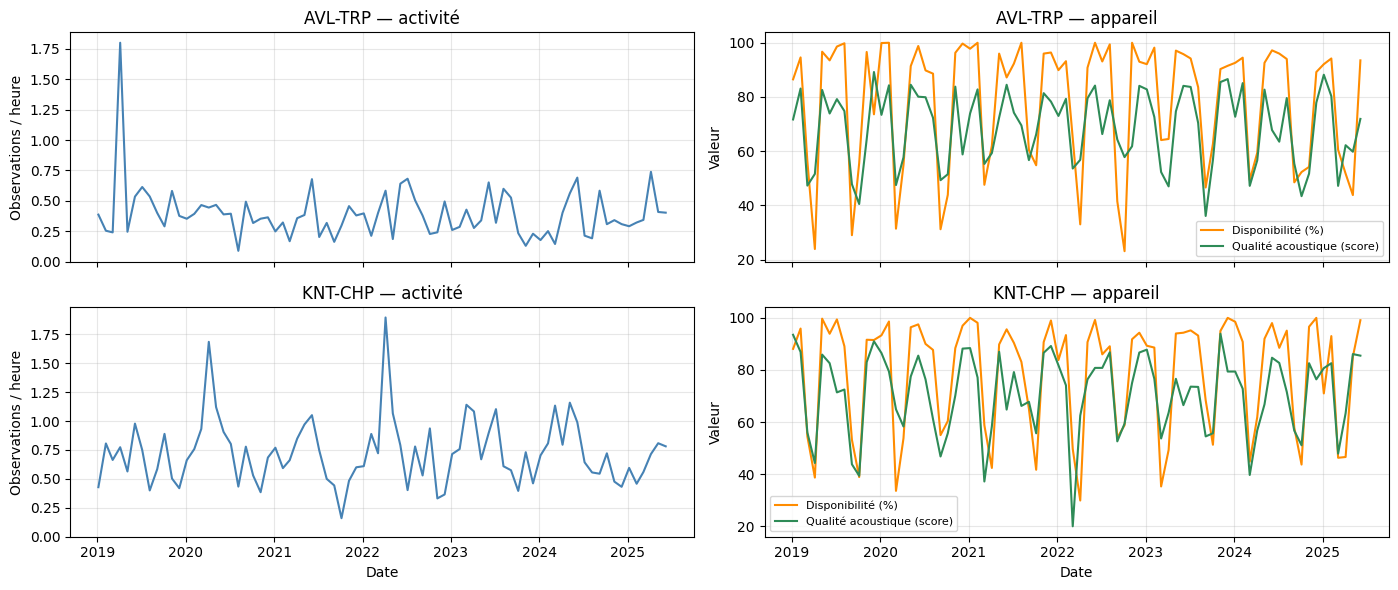

In [24]:
eco_utils.plot_activity_and_device_quality(
    bats_devices,
    ["AVL-TRP", "KNT-CHP"]
)

### Interprétation des deux sites les plus concernés

AVL-TRP et KNT-CHP présentent des baisses répétées de disponibilité
et de qualité acoustique. Les difficultés techniques ne se limitent
donc pas à un événement isolé.

Les variations de l’activité observée ne suivent toutefois pas
systématiquement ces baisses. Les graphiques ne permettent pas
d’attribuer chaque variation d’activité à un problème technique.

Ces deux sites seront interprétés avec prudence dans la suite
de l’étude. Une baisse écologique supposée devra être confrontée
aux conditions de mesure du mois concerné.

### Bilan de la fiabilité des capteurs

Les 4 992 relevés ont été associés aux informations de fonctionnement
des appareils du même site et du même mois.

Sur les 64 sites, les corrélations entre activité, disponibilité
et qualité acoustique sont généralement proches de zéro.
Il n’apparaît donc pas d’association monotone forte commune
à l’ensemble des sites.

Les 189 relevés avec panne déclarée présentent généralement
une disponibilité et une qualité acoustique inférieures
à la référence du même site et du même mois de l’année.
L’activité observée ne montre cependant pas de baisse uniforme
dans cette comparaison.

Les quatre prestataires suivent chacun 16 sites, sans changement
de prestataire au sein d’un site. Cette organisation ne permet pas
de distinguer leur effet propre de celui des sites et des appareils.

AVL-TRP et KNT-CHP concentrent une proportion particulièrement
élevée de pannes déclarées, accompagnées de dégradations techniques
répétées. Leurs résultats nécessitent une attention particulière.

Les problèmes techniques doivent donc être considérés lors
de l’interprétation des variations, mais ils ne fournissent pas
une explication générale suffisante des évolutions observées.

## 4. Conditions environnementales

### 4.1. Préparation des données

Nous associons les relevés de chauves-souris aux conditions
environnementales du même site et du même mois : météo,
végétation, perturbation de l’habitat et pesticides.

Tous les relevés sont conservés. Les mois absents du fichier
environnemental restent sans valeur pour ces variables.

In [25]:

environment = pd.read_csv(
    data_path / "environmental_monthly.csv",
    parse_dates=["reporting_month"]
)

bats_environment = eco_utils.link_surveys_to_environment(
    bats_devices,
    environment
)

### 4.2. Relations avec les conditions environnementales

Nous calculons les corrélations de Spearman entre l’activité
observée et les variables environnementales, séparément pour
chaque site étudié.

Une corrélation positive indique que les deux variables tendent
à augmenter ensemble. Une corrélation négative indique
des évolutions de sens opposé.

Les valeurs manquantes sont exclues uniquement du calcul concerné.
Ces associations ne démontrent pas de causalité et peuvent notamment
refléter une saisonnalité commune.

In [26]:
environment_variables = [
    "mean_temperature_c",
    "rainfall_mm",
    "mean_humidity_pct",
    "vegetation_cover_pct",
    "habitat_disturbance_index",
    "pesticide_index"
]

environment_correlations = eco_utils.correlations_by_site(
    bats_environment,
    selected_sites,
    environment_variables
)

display(environment_correlations.round(3))

,site_code,variable,nombre_paires,spearman
0,TMB-BRC,mean_temperature_c,78,-0.043
1,TMB-BRC,rainfall_mm,78,0.188
2,TMB-BRC,mean_humidity_pct,78,0.185
3,TMB-BRC,vegetation_cover_pct,78,0.136
4,TMB-BRC,habitat_disturbance_index,78,-0.100
5,TMB-BRC,pesticide_index,78,-0.366
6,KNT-KES,mean_temperature_c,78,0.463
7,KNT-KES,rainfall_mm,78,0.138
8,KNT-KES,mean_humidity_pct,78,0.056
9,KNT-KES,vegetation_cover_pct,78,-0.017


### Corrélations entre activité et environnement

La carte présente les corrélations de Spearman pour chaque site.

Le rouge indique une association positive, le bleu une association
négative. Les couleurs proches du blanc correspondent à des
corrélations proches de zéro. L’échelle est identique pour tous
les sites, de −1 à 1.

Les coefficients décrivent des associations et ne démontrent
pas de relation causale.

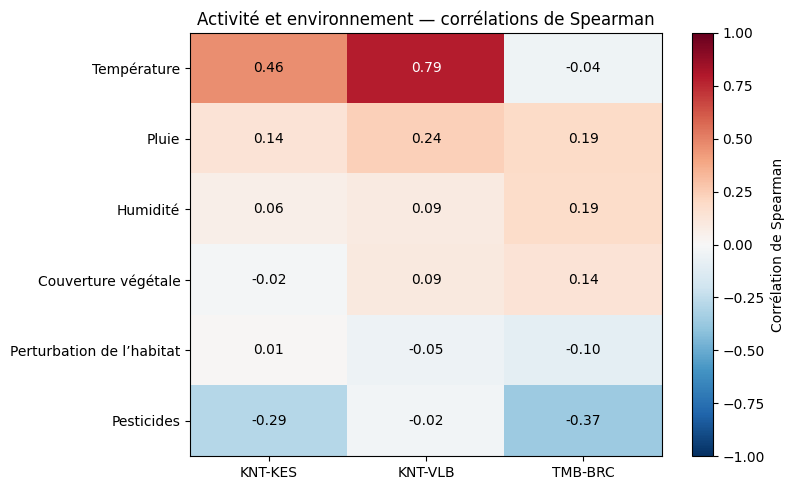

In [27]:

eco_utils.plot_environment_correlations(environment_correlations)

### 4.3. Forme des relations avec l’environnement

La carte de corrélations met en évidence une association positive
avec la température à KNT-VLB et KNT-KES, ainsi qu’une association
négative avec les pesticides à TMB-BRC et KNT-KES.

Nous représentons ces quatre relations pour examiner leur forme
et leur dispersion. Chaque point correspond à un mois de suivi.

Ces graphiques restent exploratoires : ils ne permettent pas
de séparer l’effet des variables de celui de la saisonnalité.

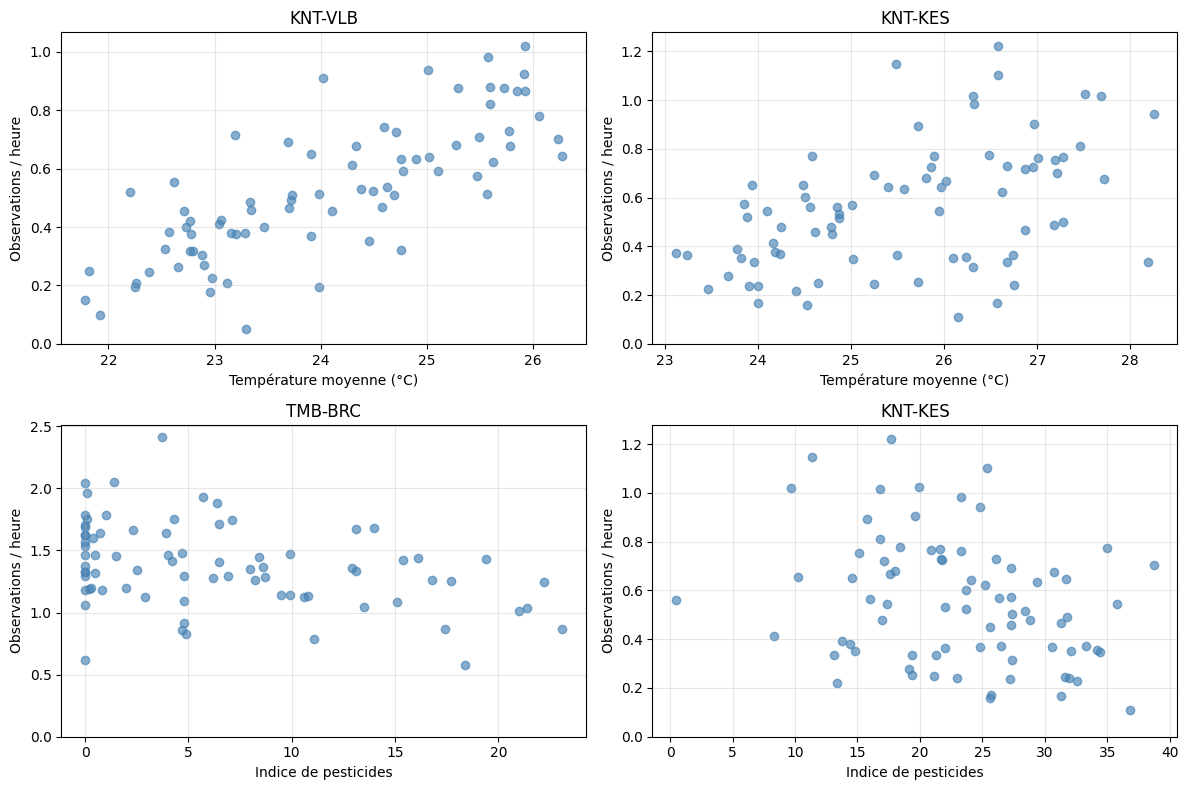

In [28]:

eco_utils.plot_selected_environment_relationships(bats_environment)

### Interprétation

À KNT-VLB, l’activité observée augmente généralement avec
la température. À KNT-KES, cette tendance est également visible,
mais les observations sont davantage dispersées : une même
température peut correspondre à des niveaux d’activité différents.

À TMB-BRC et à KNT-KES, les observations suggèrent une tendance
négative avec l’indice de pesticides. La dispersion reste importante,
ce qui indique que cet indice ne résume pas toutes les variations.

Ces relations peuvent être influencées par la saisonnalité.
Nous examinons donc si elles persistent après retrait
du profil saisonnier moyen de chaque site.

### 4.4. Associations après retrait du profil saisonnier moyen

Pour chaque site et chaque variable, nous soustrayons la moyenne
du mois de l’année correspondant. Nous comparons ensuite
les écarts obtenus avec les corrélations précédentes.

Cette approche permet d’examiner les associations au-delà
du profil saisonnier moyen. Elle reste exploratoire : elle ne
contrôle pas tous les facteurs et ne démontre pas de causalité.

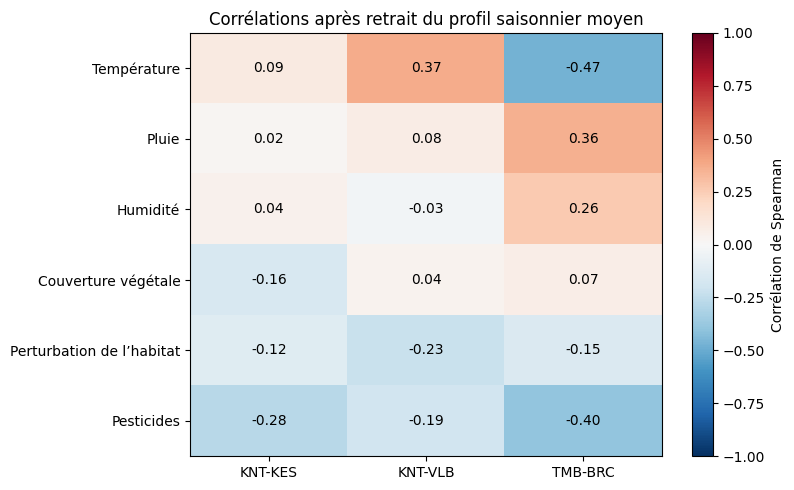

In [29]:
seasonal_deviations = eco_utils.remove_average_seasonality(
    bats_environment,
    ["bats_per_hour"] + environment_variables
)

adjusted_correlations = eco_utils.correlations_by_site(
    seasonal_deviations,
    selected_sites,
    [
        f"{variable}_deviation"
        for variable in environment_variables
    ],
    target="bats_per_hour_deviation"
)

adjusted_correlations["variable"] = (
    adjusted_correlations["variable"]
    .str.removesuffix("_deviation")
)
eco_utils.plot_environment_correlations(
    adjusted_correlations,
    title="Corrélations après retrait du profil saisonnier moyen"
)

### Interprétation après retrait du profil saisonnier moyen

À KNT-KES, la corrélation avec la température passe de 0,46
à 0,09. L’association initiale semble donc principalement liée
au profil saisonnier commun des deux variables.

À KNT-VLB, cette corrélation diminue de 0,79 à 0,37.
Une association positive persiste entre les écarts de température
et d’activité, mais elle est moins marquée que dans les données brutes.

À TMB-BRC, la corrélation avec la température devient négative
(−0,47), alors qu’elle était proche de zéro auparavant.
Le profil saisonnier pouvait donc masquer une association
différente entre les écarts mensuels.

Les associations avec les pesticides restent négatives :
environ −0,28 à KNT-KES, −0,19 à KNT-VLB et −0,40 à TMB-BRC.

Ces résultats montrent que les corrélations brutes peuvent changer
après prise en compte du profil saisonnier moyen. Ils ne démontrent
pas un effet causal : les tendances temporelles et les autres
facteurs ne sont pas tous contrôlés.

### 4.5. Comparaison sur l’ensemble des sites

Les trois sites précédents ont été sélectionnés pour leurs fortes
variations d’activité. Ils ne représentent pas nécessairement
l’ensemble des sites suivis.

Nous calculons donc les corrélations sur les 64 sites, avant
et après retrait du profil saisonnier moyen.

La distribution des coefficients permet d’examiner si les
associations sont communes ou différentes selon les sites.
Chaque site contribue par un coefficient à chaque distribution.

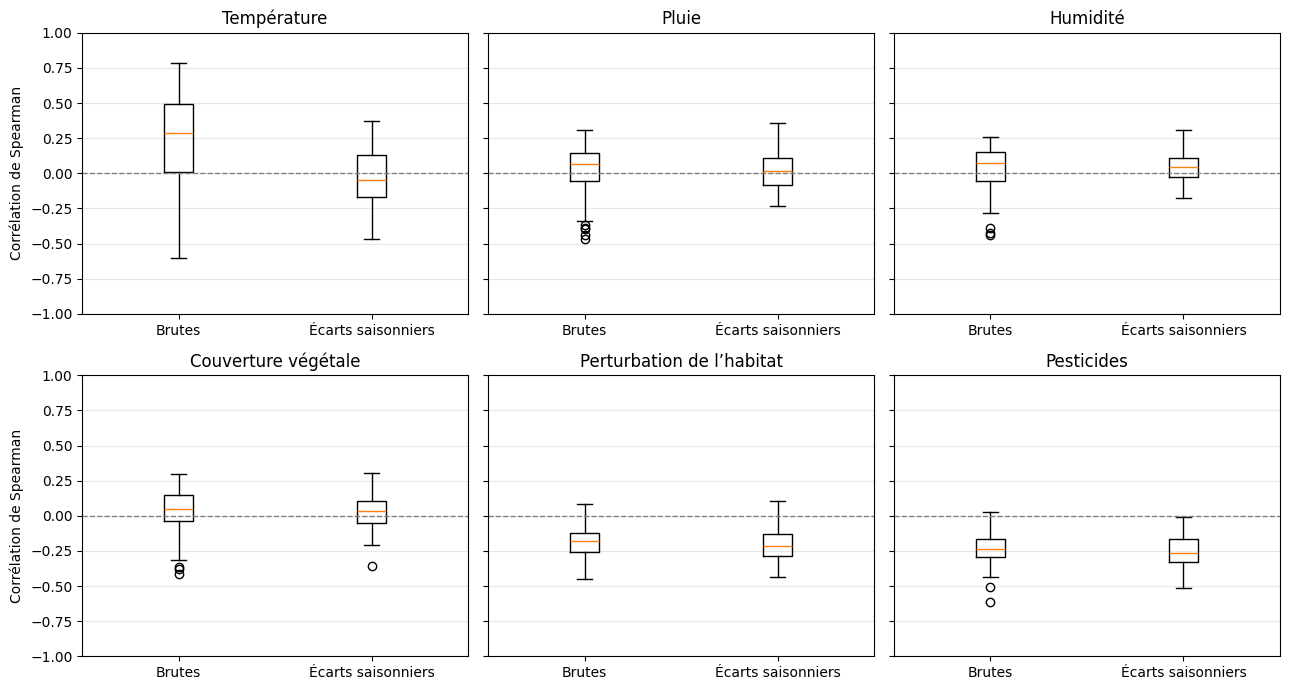

In [30]:

all_sites = bats_environment["site_code"].unique().tolist()

all_raw_correlations = eco_utils.correlations_by_site(
    bats_environment,
    all_sites,
    environment_variables
)

all_adjusted_correlations = eco_utils.correlations_by_site(
    seasonal_deviations,
    all_sites,
    [f"{variable}_deviation" for variable in environment_variables],
    target="bats_per_hour_deviation"
)

all_adjusted_correlations["variable"] = (
    all_adjusted_correlations["variable"]
    .str.removesuffix("_deviation")
)

eco_utils.plot_correlation_distributions(
    all_raw_correlations,
    all_adjusted_correlations
)

### Interprétation sur l’ensemble des sites

Les corrélations brutes avec la température sont souvent positives.
Après retrait du profil saisonnier moyen, leur distribution
se recentre autour de zéro. Une partie importante de l’association
initiale semble donc liée à la saisonnalité.

Les corrélations avec la pluie, l’humidité et la couverture végétale
restent généralement proches de zéro, malgré des différences
entre les sites.

Les associations avec les pesticides et la perturbation de l’habitat
restent généralement négatives après cette transformation.
Ces variables constituent des pistes à approfondir.

Ces résultats décrivent des associations individuelles par site.
Ils ne mesurent pas l’effet propre de chaque facteur et ne permettent
pas d’expliquer à eux seuls les baisses observées sur certaines périodes.

### Bilan des associations environnementales

Les relations entre l’activité observée et l’environnement
diffèrent selon les sites.

Sur l’ensemble des 64 sites, les corrélations positives avec
la température diminuent nettement après retrait du profil
saisonnier moyen. Leur distribution se recentre autour de zéro :
une partie de l’association initiale semble liée à la saisonnalité.

Les corrélations avec la pluie, l’humidité et la couverture
végétale restent généralement proches de zéro. Les associations
avec les pesticides et la perturbation de l’habitat restent
généralement négatives.

Les facteurs environnementaux constituent donc des pistes
d’explication, mais ces analyses ne mesurent pas leur effet propre
et ne démontrent pas de causalité.

Les 25 mois absents du fichier environnemental préparé restent
sans information environnementale dans la table de rapprochement.

## 5. Activité des chauves-souris et production des vergers

### 5.1. Préparation des données

Nous rapprochons les relevés des vergers de l’activité observée
et des conditions environnementales du même site et du même mois.

Nous calculons également le rendement par hectare pour comparer
des vergers de surfaces différentes.

Les taux de fructification dont l’échelle est incertaine restent
inchangés. Leur influence devra être examinée lors de l’interprétation.

In [31]:

orchards = pd.read_csv(
    data_path / "orchard_surveys.csv",
    parse_dates=["survey_period"]
)

orchard_analysis = eco_utils.prepare_orchard_analysis(
    orchards,
    bats_environment
)

display(
    orchard_analysis[
        [
            "site_code",
            "survey_period",
            "bats_per_hour",
            "fruit_set_rate_pct",
            "yield_kg_per_ha"
        ]
    ].head()
)

,site_code,survey_period,bats_per_hour,fruit_set_rate_pct,yield_kg_per_ha
0,AVL-MAR,2019-01-01,0.061728,34.7,846.506224
1,AVL-MAR,2019-02-01,0.175953,41.6,734.966805
2,AVL-MAR,2019-03-01,0.376176,57.3,1199.190871
3,AVL-MAR,2019-04-01,0.258621,48.7,912.568465
4,AVL-MAR,2019-05-01,0.639535,61.4,1129.190871


### 5.2. Relations avec la fructification et le rendement

Nous représentons le taux de fructification et le rendement
par hectare en fonction de l’activité observée des chauves-souris.

Chaque point correspond à un site et à un mois. Les couleurs
permettent de distinguer les sites et de repérer si une tendance
globale reflète surtout des différences entre vergers.

Ces graphiques décrivent des associations contemporaines.
Ils ne démontrent pas un effet causal de pollinisation et ne prennent
pas encore en compte les décalages possibles entre activité,
fructification et récolte.

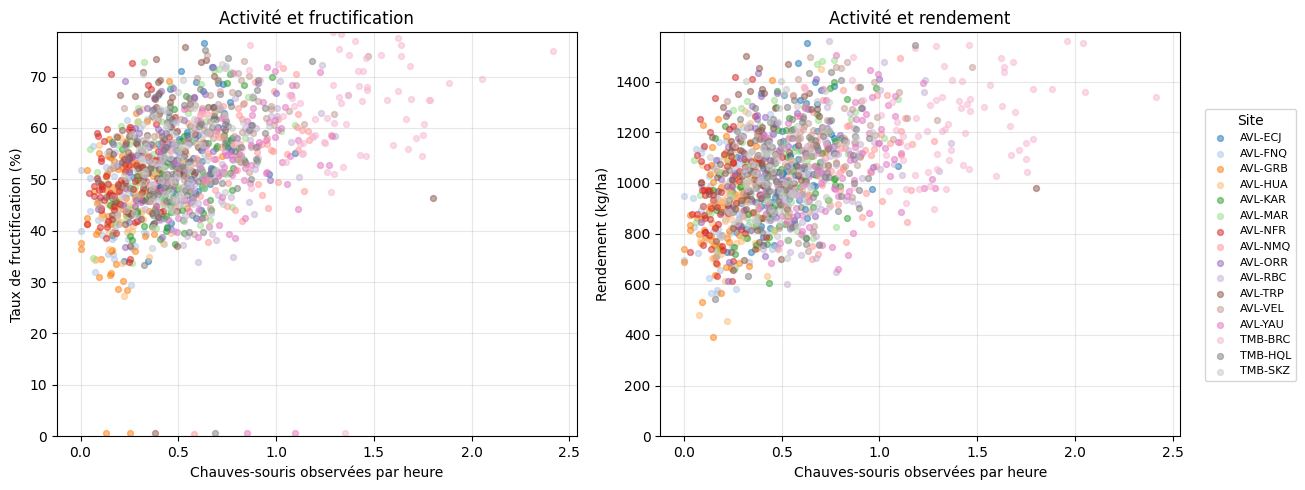

In [32]:

eco_utils.plot_orchard_relationships(orchard_analysis)

### Première interprétation

L’activité observée des chauves-souris présente une association
visuellement positive avec la fructification et le rendement
par hectare. La dispersion reste importante.

Cette tendance globale peut combiner des variations au sein
des vergers et des différences entre sites. Nous calculons donc
les corrélations séparément pour chaque verger.

Pour la fructification, nous comparons également les résultats
avec et sans les taux strictement compris entre 0 et 1 %,
dont l’échelle est incertaine. Cette comparaison constitue
une analyse de sensibilité, sans modification des données.

### 5.3. Associations au sein des vergers

Chaque boîte résume les corrélations calculées séparément
pour les différents vergers. Chaque verger contribue par
un coefficient, calculé sur ses mois de suivi.

La comparaison des deux premières boîtes permet d’examiner
l’influence des taux de fructification dont l’échelle est incertaine.

Ces corrélations ne contrôlent pas encore la saisonnalité,
les pratiques agricoles ou les décalages entre activité et récolte.

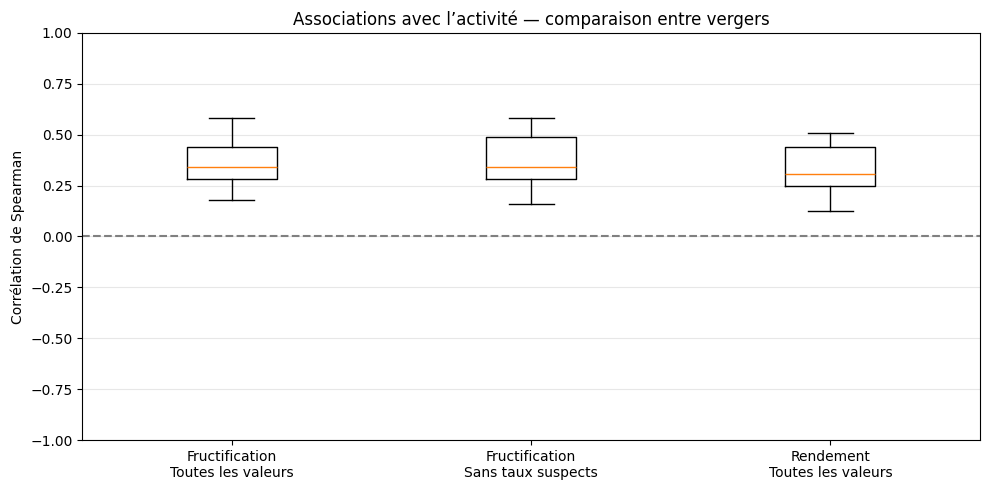

In [33]:

orchard_correlations = eco_utils.plot_orchard_correlations(
    orchard_analysis
)

### Interprétation

Les corrélations avec la fructification sont positives dans les
vergers étudiés, avec une médiane visuellement proche de 0,34.

Le retrait temporaire des taux dont l’échelle est incertaine
modifie peu la distribution. L’association positive ne semble
donc pas dépendre uniquement de ces observations.

Les corrélations avec le rendement par hectare sont également
positives, avec une médiane proche de 0,30.

Ces résultats restent descriptifs. Une saison favorable peut
augmenter simultanément l’activité observée et la production.
Nous examinons donc l’influence du profil saisonnier moyen.

### 5.4. Influence de la saisonnalité

Nous comparons les corrélations par verger avant et après retrait
du profil mensuel moyen de chaque variable.

Les taux de fructification dont l’échelle est incertaine sont
temporairement exclus des deux calculs de fructification.
Les données principales restent inchangées.

Cette comparaison examine les associations au-delà du profil
saisonnier moyen, sans contrôler tous les facteurs agricoles
ni les décalages possibles entre activité et récolte.

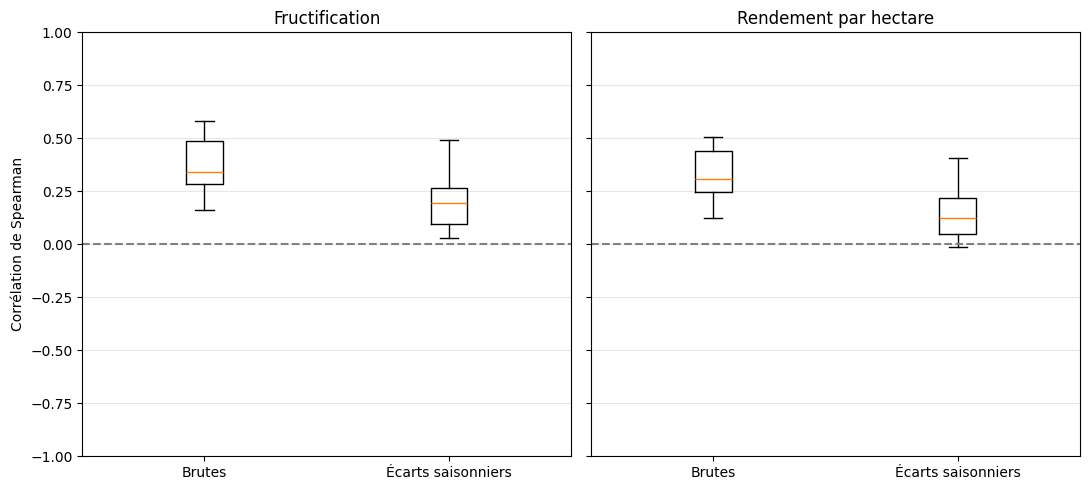

In [34]:

orchard_seasonal_comparison = (
    eco_utils.plot_orchard_seasonal_comparison(orchard_analysis)
)

### Interprétation après prise en compte de la saisonnalité

Pour la fructification, la médiane des corrélations passe
visuellement d’environ 0,34 à 0,19. Pour le rendement par hectare,
elle passe d’environ 0,30 à 0,12.

Une partie des associations initiales semble donc liée
à la saisonnalité commune des variables. Les corrélations
restent généralement positives, mais leur amplitude diminue.

Ces résultats sont compatibles avec un lien entre l’activité
observée et la production des vergers, sans démontrer
un mécanisme de pollinisation ni son importance causale.

Les pratiques agricoles, les autres pollinisateurs, la météo
et les décalages entre floraison et récolte restent à considérer.

### 5.5. Pratiques agricoles et autres facteurs

La production des vergers peut également être associée aux pesticides,
à la fertilisation, à l’irrigation, à la densité florale
et à l’activité des autres pollinisateurs.

Nous examinons leurs associations avec la fructification
et le rendement, séparément pour chaque verger et après retrait
du profil saisonnier moyen.

Ces comparaisons complètent l’étude de l’activité des chauves-souris.
Elles ne permettent pas d’isoler l’effet propre de chaque facteur.

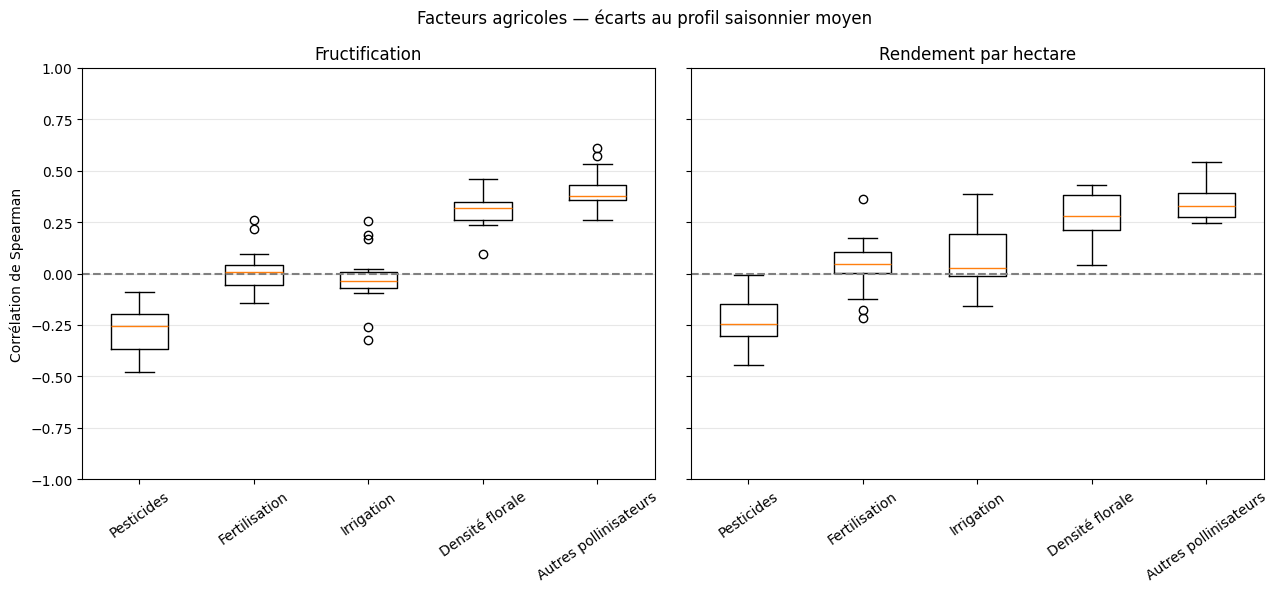

In [35]:

orchard_factor_correlations = (
    eco_utils.plot_orchard_factor_correlations(orchard_analysis)
)

### Interprétation des facteurs agricoles

Après retrait du profil saisonnier moyen, les pesticides présentent
des associations généralement négatives avec la fructification
et le rendement par hectare. La médiane des coefficients est
visuellement proche de −0,25 pour les deux indicateurs.

La densité florale et l’activité des autres pollinisateurs
présentent des associations positives avec les deux indicateurs
de production.

Les associations avec la fertilisation et l’irrigation sont
généralement proches de zéro, avec des différences entre vergers.
Cela ne démontre pas une absence d’effet de ces pratiques.

La production varie donc avec plusieurs facteurs. Les corrélations
calculées séparément ne permettent pas de déterminer leurs effets
propres ni d’attribuer la production aux seules chauves-souris.

### Bilan de l’étude des vergers

L’activité observée des chauves-souris est positivement associée
à la fructification et au rendement par hectare dans les vergers
étudiés. Le retrait temporaire des taux de fructification
dont l’échelle est incertaine modifie peu ce résultat.

Après retrait du profil saisonnier moyen, ces associations
diminuent mais restent généralement positives. Une partie
des relations initiales semble donc liée à la saisonnalité.

La densité florale et l’activité des autres pollinisateurs
présentent également des associations positives avec la production.
Les associations avec les pesticides sont généralement négatives.

Ces résultats soulignent la présence de plusieurs facteurs associés
à la production. Ils sont compatibles avec une contribution
des chauves-souris à la pollinisation, sans démontrer ce mécanisme
ni permettre d’en quantifier l’effet propre.

Les décalages entre activité, floraison, fructification et récolte
n’ont pas été étudiés.

## 6. Accès aux sites et variations d’activité

### 6.1. Identification des accès effectifs

Le journal des accès décrit les étapes des dossiers :
demande, examen, autorisation et intervention.

Nous identifions les événements correspondant au début effectif
d’un accès. Une autorisation seule ne garantit pas qu’une intervention
a eu lieu.

La date d’accès servira ensuite de référence pour comparer
l’activité observée avant et après l’intervention.

In [36]:
access_path = PROJECT_ROOT / "data" / "public_records" / "site_access_case_events.csv"

access_events = pd.read_csv(access_path)

access_events["event_time"] = pd.to_datetime(
    access_events["event_time"],
    format="mixed",
    errors="raise"
)

access_events["activity"] = (
    access_events["activity"]
    .str.strip()
    .str.lower()
)

display(access_events["activity"].value_counts())

activity
request_submitted        63
closure_recorded         61
technical_review         60
access_started           54
authorization_granted    54
access_completed         54
wildlife_review          46
security_review          12
authorization_denied      9
Name: count, dtype: int64

### 6.2. Sélection des interventions commencées

Nous retenons les événements access_started, qui correspondent
au début effectif d’un accès au site.

Les doublons exacts sont retirés pour éviter de compter deux fois
un même événement.

Les relevés écologiques étant mensuels, les comparaisons porteront
sur les mois précédant et suivant l’accès. Le mois de l’intervention
sera étudié séparément, car son relevé peut avoir été réalisé
avant le début de l’accès.

In [37]:
access_events = access_events.drop_duplicates().copy()

site_accesses = (
    access_events.loc[
        access_events["activity"].eq("access_started"),
        [
            "access_case_number",
            "site_code",
            "event_time",
            "requesting_organization_name",
            "access_purpose"
        ]
    ]
    .sort_values("event_time")
    .reset_index(drop=True)
)

print("Nombre d’accès commencés :", len(site_accesses))
print("Nombre de sites concernés :", site_accesses["site_code"].nunique())
print("Premier accès :", site_accesses["event_time"].min())
print("Dernier accès :", site_accesses["event_time"].max())

display(site_accesses.head())

Nombre d’accès commencés : 54
Nombre de sites concernés : 44
Premier accès : 2015-03-01 17:00:00
Dernier accès : 2025-06-12 18:00:00


,access_case_number,site_code,event_time,requesting_organization_name,access_purpose
0,ACC-2015-0034,KNT-VXR,2015-03-01 17:00:00,Orison Facility Management,sensor maintenance
1,ACC-2015-0029,KNT-DMJ,2015-11-15 17:00:00,Nordhaven Maritime Safety Agency,emergency equipment recovery
2,ACC-2016-0046,AVL-RBC,2016-03-02 17:00:00,Kintara Emergency Response Office,orchard pollination survey
3,ACC-2017-0039,AVL-NFR,2017-02-24 17:00:00,Juniper Community Health Foundation,emergency equipment recovery
4,ACC-2017-0044,AVL-RNY,2017-06-09 17:00:00,Blue Heron Monitoring Cooperative,habitat restoration assessment


### 6.3. Construction des fenêtres avant et après accès

Pour chaque accès, nous recherchons les relevés des trois mois
précédents et des trois mois suivants sur le même site.

Le mois de l’accès est exclu : le relevé peut précéder l’intervention.
Nous retenons pour la comparaison les accès disposant des six mois.

Cette fenêtre décrit les variations proches de l’intervention.
Une différence avant/après ne démontre pas un effet de l’accès :
la saisonnalité et les autres facteurs devront être considérés.

In [38]:

access_windows, access_summary = eco_utils.build_access_windows(
    site_accesses,
    bats
)

eligible_accesses = access_summary.loc[
    access_summary["fenetre_complete"]
].copy()

print("Accès étudiables :", len(eligible_accesses))
print(
    "Accès sans fenêtre complète :",
    len(access_summary) - len(eligible_accesses)
)

display(
    eligible_accesses[
        ["access_case_number", "site_code", "access_date", "organization"]
    ].head()
)

Accès étudiables : 39
Accès sans fenêtre complète : 15


,access_case_number,site_code,access_date,organization
13,ACC-2019-0004,TMB-PEL,2019-08-08 18:00:00,Horizon Field Research Cooperative
14,ACC-2019-0005,KNT-LUM,2019-09-12 18:00:00,Horizon Field Research Cooperative
15,ACC-2019-0027,KNT-YRG,2019-09-18 17:00:00,Kintara Rural Transport Board
16,ACC-2019-0036,KNT-BME,2019-09-19 17:00:00,Senna Agricultural Research Centre
17,ACC-2019-0035,KNT-TEX,2019-09-23 17:00:00,Lumen Protective Equipment


### 6.4. Première comparaison avant et après accès

Pour chaque accès retenu, nous calculons la médiane de l’activité
des trois mois précédents et celle des trois mois suivants.

Sur le premier graphique, chaque point représente un accès.
Les points sous la diagonale correspondent à une activité
plus faible après l’intervention.

Le second graphique présente les différences après moins avant.
Cette comparaison est descriptive : elle ne corrige pas encore
la saisonnalité et ne démontre pas un effet de l’accès.

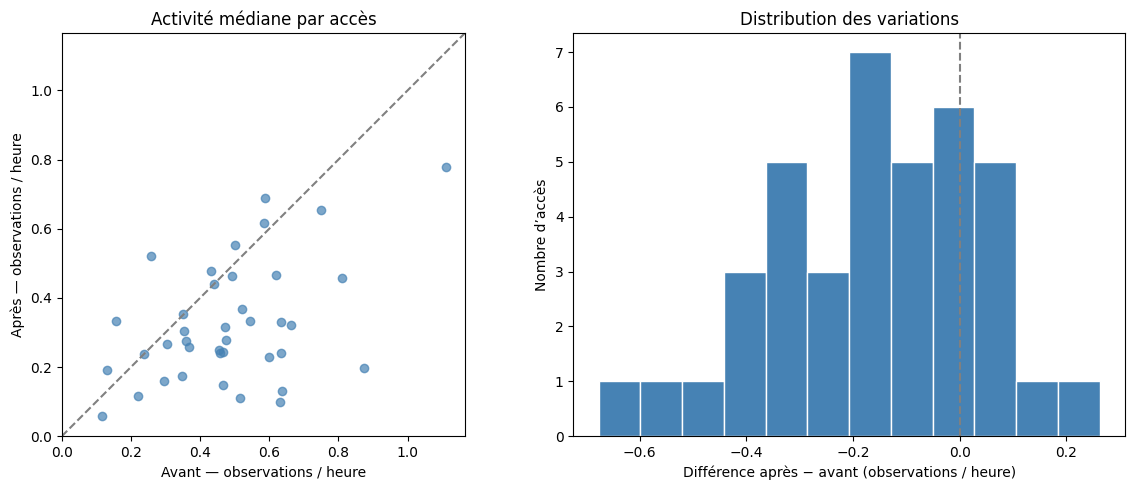

Nombre d’accès analysés : 39


In [39]:
access_comparison = eco_utils.plot_access_before_after(
    access_windows,
    eligible_accesses
)

print("Nombre d’accès analysés :", len(access_comparison))

### Première interprétation avant et après accès

La comparaison brute montre davantage de diminutions que
d’augmentations de l’activité après les accès étudiés.

Les variations sont toutefois hétérogènes : certains accès
sont suivis d’une hausse ou d’un changement limité.

Ce résultat ne permet pas d’attribuer les baisses aux interventions.
Le calendrier des accès peut notamment coïncider avec
les variations saisonnières de l’activité.

### 6.5. Comparaison avec une référence saisonnière

Pour chaque accès, nous calculons l’activité habituelle de chaque
mois de l’année sur le même site, à partir des autres périodes.

La fenêtre allant de trois mois avant à trois mois après l’accès
est exclue de cette référence pour éviter d’y inclure
les observations étudiées.

Nous calculons les écarts entre l’activité observée et cette
référence, puis comparons leurs médianes avant et après l’accès.

Cette approche tient compte du profil saisonnier du site,
mais ne contrôle pas tous les facteurs ni les autres interventions.

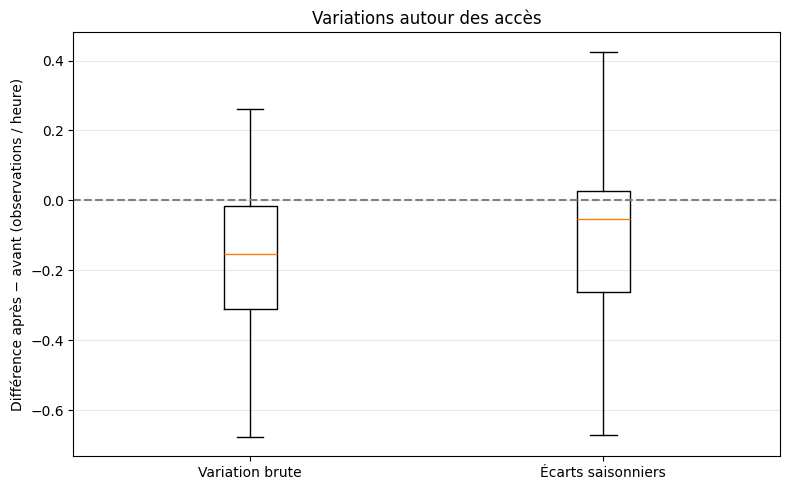

In [40]:
access_seasonal_comparison = eco_utils.compare_access_seasonality(
    access_windows,
    eligible_accesses,
    bats,
    access_comparison
)

### Interprétation après prise en compte de la saisonnalité

La variation médiane devient moins négative après retrait
de la référence saisonnière : elle passe visuellement d’environ
−0,15 à −0,05 observation par heure.

Une partie de la baisse observée dans la comparaison brute
semble donc liée au calendrier des interventions.

Les résultats restent hétérogènes, avec des diminutions
et des augmentations après retrait de la référence saisonnière.
Il n’apparaît pas de baisse uniforme après tous les accès.

Nous examinons maintenant les accès présentant les variations
négatives les plus importantes. Ce classement sert à sélectionner
des cas à approfondir, sans constituer une preuve d’effet causal.

### 6.6. Identification des cas à approfondir

Nous classons les accès selon leur variation après retrait
de la référence saisonnière.

Pour les cas présentant les baisses les plus importantes,
nous examinerons les conditions techniques, l’environnement
et les sites comparables avant de proposer une interprétation.

In [41]:
accesses_to_review = (
    access_seasonal_comparison
    .sort_values("difference_saisonniere")
    .head(10)
)

display(
    accesses_to_review[
        [
            "access_case_number",
            "site_code",
            "access_date",
            "organization",
            "avant",
            "apres",
            "difference",
            "difference_saisonniere"
        ]
    ].round(3)
)

,access_case_number,site_code,access_date,organization,avant,apres,difference,difference_saisonniere
11,ACC-2021-0009,KNT-KES,2021-03-25 18:00:00,Horizon Field Research Cooperative,0.635,0.242,-0.393,-0.672
31,ACC-2024-0014,KNT-KES,2024-03-21 18:00:00,Horizon Field Research Cooperative,0.545,0.334,-0.210,-0.578
17,ACC-2022-0011,TMB-NAC,2022-02-17 18:00:00,Horizon Field Research Cooperative,0.638,0.130,-0.508,-0.573
1,ACC-2019-0005,KNT-LUM,2019-09-12 18:00:00,Horizon Field Research Cooperative,0.630,0.098,-0.532,-0.487
33,ACC-2024-0055,AVL-NMQ,2024-06-29 17:00:00,Valenne Laboratory Materials,1.111,0.779,-0.332,-0.476
30,ACC-2023-0013,AVL-VEL,2023-11-09 18:00:00,Horizon Field Research Cooperative,0.874,0.197,-0.677,-0.444
23,ACC-2022-0023,KNT-JAK,2022-11-01 17:00:00,Avelora Orchard Export Union,0.520,0.367,-0.153,-0.372
9,ACC-2020-0008,AVL-ORR,2020-06-11 18:00:00,Horizon Field Research Cooperative,0.476,0.278,-0.198,-0.342
27,ACC-2023-0012,KNT-LUM,2023-09-14 18:00:00,Horizon Field Research Cooperative,0.515,0.109,-0.406,-0.322
36,ACC-2024-0016,TMB-PEL,2024-08-15 18:00:00,Horizon Field Research Cooperative,0.466,0.147,-0.318,-0.262


### Première lecture des cas sélectionnés

Horizon Field Research Cooperative est l’organisation demandeuse
pour 8 des 10 accès associés aux plus fortes variations négatives
après retrait de la référence saisonnière.

Deux sites, KNT-KES et KNT-LUM, apparaissent à plusieurs reprises.
Ces événements ne constituent donc pas tous des observations
sur des sites indépendants.

Ce résultat suggère une piste, mais ne suffit pas à établir
un lien propre à l’organisation. Nous comparons ses accès
à tous les autres accès étudiables, sans nous limiter
aux cas présentant une baisse.

### 6.7. Comparaison selon l’organisation demandeuse

Nous comparons les variations autour des accès demandés par
Horizon Field Research Cooperative à celles des autres organisations.

Chaque point représente un accès. Les effectifs et le nombre
de sites sont indiqués pour contextualiser les distributions.

Cette comparaison reste exploratoire : les organisations
n’interviennent pas nécessairement sur des sites comparables,
aux mêmes saisons ou pour les mêmes motifs.

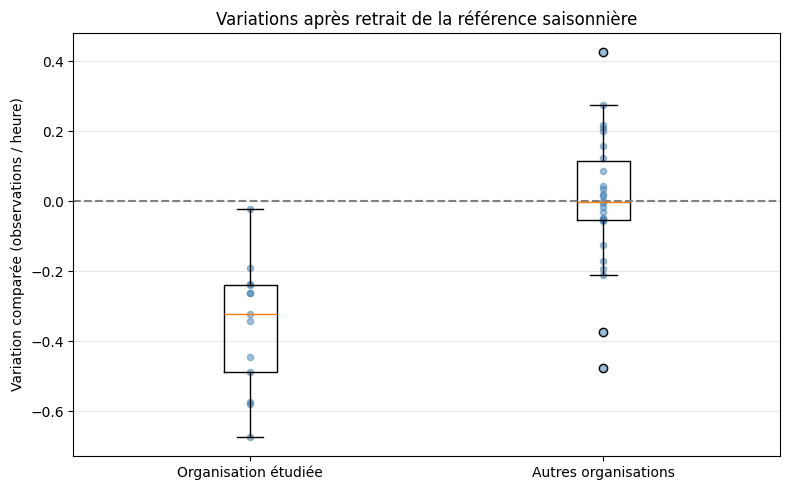

,nombre_acces,nombre_sites,variation_mediane
groupe,,,
Organisation étudiée,13,8,-0.322
Autres organisations,26,26,-0.002


In [42]:

organization_comparison = eco_utils.compare_access_organization(
    access_seasonal_comparison,
    "Horizon Field Research Cooperative"
)

display(organization_comparison.round(3))

### Interprétation selon l’organisation demandeuse

Après retrait de la référence saisonnière, les accès d’Horizon
présentent une variation médiane de −0,322 observation par heure,
contre −0,002 pour les autres organisations.

La baisse observée ne semble donc pas concerner uniformément
tous les accès. Elle est plus marquée dans le groupe Horizon.

Cette comparaison ne démontre pas un effet propre à l’organisation.
Ses 13 accès concernent 8 sites, contre 26 sites pour les autres
organisations. Les caractéristiques des sites, les conditions
environnementales et les interventions répétées peuvent intervenir.

Nous recherchons maintenant des sites comparables suivis
aux mêmes dates.

### 6.8. Recherche de sites de comparaison

Pour chaque accès, nous recherchons d’autres sites appartenant
au même groupe descriptif : région, type de suivi et habitat.

Nous excluons les sites ayant un accès enregistré entre trois mois
avant et trois mois après l’intervention étudiée.

Ces sites serviront à comparer les évolutions sur les mêmes périodes.
Ils ne constituent pas des témoins parfaitement équivalents :
les conditions locales peuvent rester différentes.

In [43]:

access_comparators = eco_utils.find_access_comparison_sites(
    eligible_accesses,
    sites,
    site_accesses
)

display(
    access_comparators[
        [
            "access_case_number",
            "site_code",
            "nombre_comparateurs",
            "sites_comparateurs"
        ]
    ]
)

,access_case_number,site_code,nombre_comparateurs,sites_comparateurs
0,ACC-2019-0004,TMB-PEL,8,"[TMB-VZT, TMB-CKU, TMB-GWP, TMB-AYQ, TMB-XTD, ..."
1,ACC-2019-0005,KNT-LUM,5,"[KNT-KES, KNT-SEN, KNT-CYP, KNT-NNM, KNT-JAK]"
2,ACC-2019-0027,KNT-YRG,1,[KNT-GGN]
3,ACC-2019-0036,KNT-BME,5,"[KNT-KES, KNT-SEN, KNT-CYP, KNT-NNM, KNT-JAK]"
4,ACC-2019-0035,KNT-TEX,7,"[KNT-YRX, KNT-GKR, KNT-VLB, KNT-DMJ, KNT-TLQ, ..."
5,ACC-2019-0051,AVL-ABG,3,"[AVL-DER, AVL-BWK, AVL-SEY]"
6,ACC-2019-0045,AVL-ECJ,5,"[AVL-MAR, AVL-RBC, AVL-KAR, AVL-YAU, AVL-NMQ]"
7,ACC-2019-0006,AVL-VEL,5,"[AVL-MAR, AVL-RBC, AVL-KAR, AVL-YAU, AVL-NMQ]"
8,ACC-2020-0007,KNT-SEN,6,"[KNT-KES, KNT-LUM, KNT-CYP, KNT-NNM, KNT-JAK, ..."
9,ACC-2020-0008,AVL-ORR,0,[]


### Représentation des liens entre sites et accès

Nous construisons un graphe biparti comportant deux types de nœuds :
les sites et les événements d’accès.

Un lien relie un site à chaque accès le concernant.
Seuls les accès disposant d’une fenêtre complète avant et après
sont représentés.

Le degré d’un site correspond au nombre d’accès étudiables
qui lui sont associés. Il décrit la répétition des interventions,
sans mesurer leur impact sur l’activité des chauves-souris.

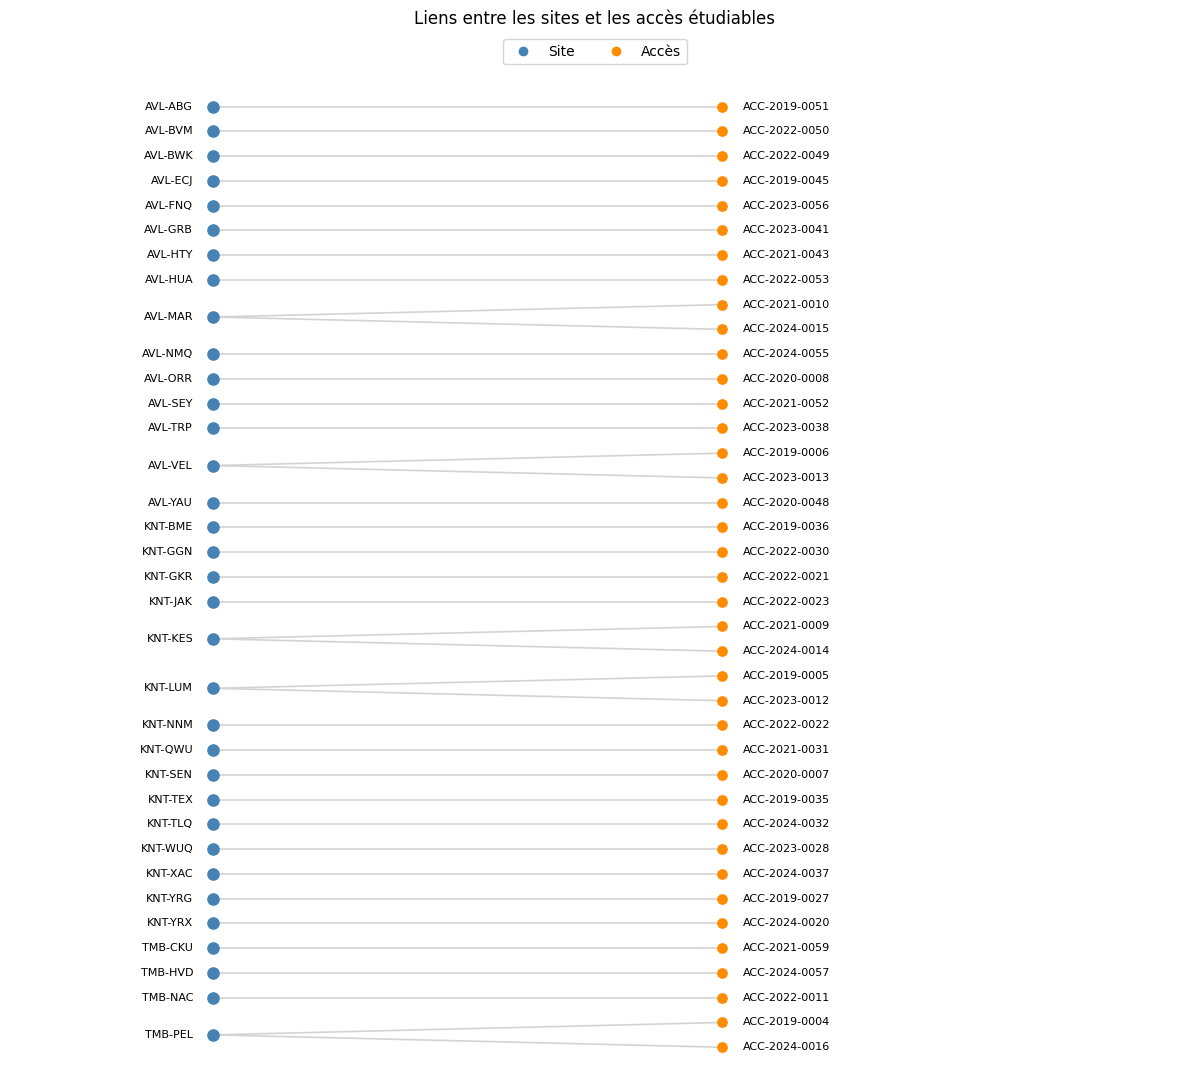

In [44]:

site_access_graph = eco_utils.plot_site_access_graph(
    eligible_accesses
)

### Interprétation du graphe sites–accès

Le graphe représente 39 accès étudiables répartis sur 34 sites.
Chaque accès est relié au site concerné.

La majorité des sites possède un seul accès dans cet ensemble.
Cinq sites en présentent deux : AVL-MAR, AVL-VEL, KNT-KES,
KNT-LUM et TMB-PEL. Leur degré est donc égal à deux.

Ces interventions répétées justifient de compléter les comparaisons
par accès avec une synthèse donnant le même poids à chaque site.

Le graphe décrit uniquement les liens entre sites et interventions.
Il ne représente ni l’intensité des opérations ni leur effet
sur l’activité des chauves-souris.

### 6.9. Comparaison des variations avec les sites similaires

Pour chaque accès disposant de comparateurs, nous calculons
la variation saisonnière des sites de comparaison aux mêmes dates.

Nous soustrayons ensuite la médiane de leurs variations
à celle du site concerné par l’accès.

Une différence négative indique une évolution moins favorable
sur le site concerné que sur ses comparateurs.

Cette comparaison reste exploratoire. Les conditions locales
et les tendances antérieures peuvent différer. Certains comparateurs
ont également pu connaître des accès en dehors de la fenêtre exclue.

In [45]:

access_peer_comparison = eco_utils.compare_access_peer_variations(
    access_seasonal_comparison,
    access_comparators,
    bats
)

display(
    access_peer_comparison.loc[
        access_peer_comparison["comparateurs_utilises"].gt(0),
        [
            "access_case_number",
            "site_code",
            "organization",
            "comparateurs_utilises",
            "difference_saisonniere",
            "variation_comparateurs",
            "difference_relative"
        ]
    ]
    .sort_values("difference_relative")
    .head(10)
    .round(3)
)

,access_case_number,site_code,organization,comparateurs_utilises,difference_saisonniere,variation_comparateurs,difference_relative
11,ACC-2021-0009,KNT-KES,Horizon Field Research Cooperative,6,-0.672,0.057,-0.729
31,ACC-2024-0014,KNT-KES,Horizon Field Research Cooperative,6,-0.578,-0.077,-0.501
1,ACC-2019-0005,KNT-LUM,Horizon Field Research Cooperative,5,-0.487,-0.010,-0.477
33,ACC-2024-0055,AVL-NMQ,Valenne Laboratory Materials,5,-0.476,-0.101,-0.375
23,ACC-2022-0023,KNT-JAK,Avelora Orchard Export Union,5,-0.372,0.002,-0.373
30,ACC-2023-0013,AVL-VEL,Horizon Field Research Cooperative,6,-0.444,-0.073,-0.371
27,ACC-2023-0012,KNT-LUM,Horizon Field Research Cooperative,6,-0.322,0.043,-0.365
8,ACC-2020-0007,KNT-SEN,Horizon Field Research Cooperative,6,-0.262,0.102,-0.364
7,ACC-2019-0006,AVL-VEL,Horizon Field Research Cooperative,5,-0.238,0.054,-0.291
6,ACC-2019-0045,AVL-ECJ,Avelora Civil Service College,5,-0.124,0.149,-0.273


### Première interprétation avec les sites comparables

Les baisses de plusieurs sites ne se retrouvent pas avec la même
amplitude chez leurs comparateurs.

KNT-KES présente notamment des différences relatives négatives
en 2021 et en 2024. Des résultats similaires apparaissent
pour certains accès à KNT-LUM et AVL-VEL.

Horizon est associé à plusieurs de ces cas, mais les baisses
ne lui sont pas exclusives.

Ces différences renforcent l’intérêt d’examiner les interventions
concernées. Elles ne démontrent pas leur responsabilité :
les conditions locales et les tendances antérieures peuvent différer.

### 6.10. Variations relatives selon l’organisation

Nous comparons les différences relatives pour tous les accès
disposant de sites comparables.

Une valeur négative indique une évolution moins favorable
sur le site concerné que sur ses comparateurs.

Cette analyse exclut les deux accès sans comparateur.
Les événements répétés sur un même site ne sont pas indépendants.

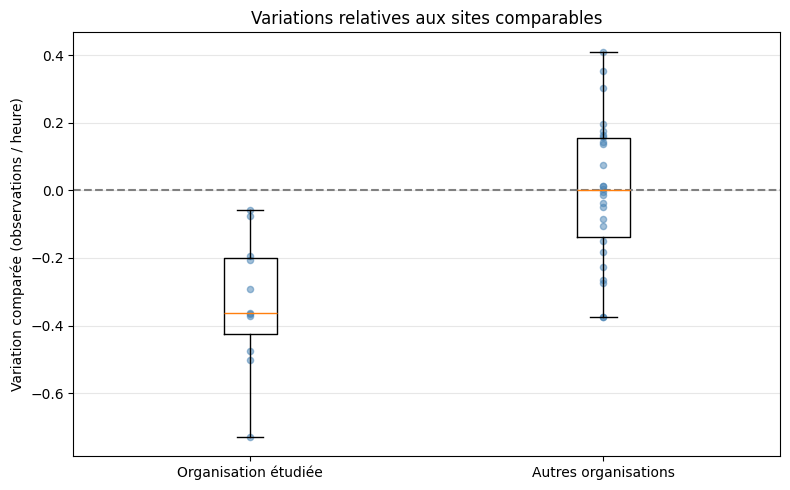

,nombre_acces,nombre_sites,variation_mediane
groupe,,,
Organisation étudiée,11,6,-0.364
Autres organisations,26,26,-0.000


In [46]:

relative_organization_comparison = eco_utils.compare_access_organization(
    access_peer_comparison,
    "Horizon Field Research Cooperative",
    value_column="difference_relative",
    title="Variations relatives aux sites comparables"
)

display(relative_organization_comparison.round(3))

### Interprétation des variations relatives

Pour les accès disposant de comparateurs, la variation relative
médiane est de −0,364 observation par heure dans le groupe Horizon,
contre une valeur proche de zéro pour les autres organisations.

Les baisses associées aux accès d’Horizon ne semblent donc pas
se résumer à l’évolution saisonnière habituelle ou à celle
des sites comparables pendant les mêmes périodes.

Ce résultat reste exploratoire. Les conditions locales peuvent
différer et les comparateurs ne sont pas parfaitement équivalents.

Les 11 accès d’Horizon concernent seulement 6 sites.
Nous vérifions donc si le contraste persiste lorsque chaque site
contribue par une seule valeur.

### 6.11. Sensibilité au nombre d’accès par site

Nous résumons les variations relatives par leur médiane
pour chaque site et chaque groupe d’organisations.

Cette comparaison réduit le poids des sites ayant plusieurs accès.
Elle ne rend pas les observations indépendantes et ne remplace
pas l’examen des conditions techniques et environnementales.

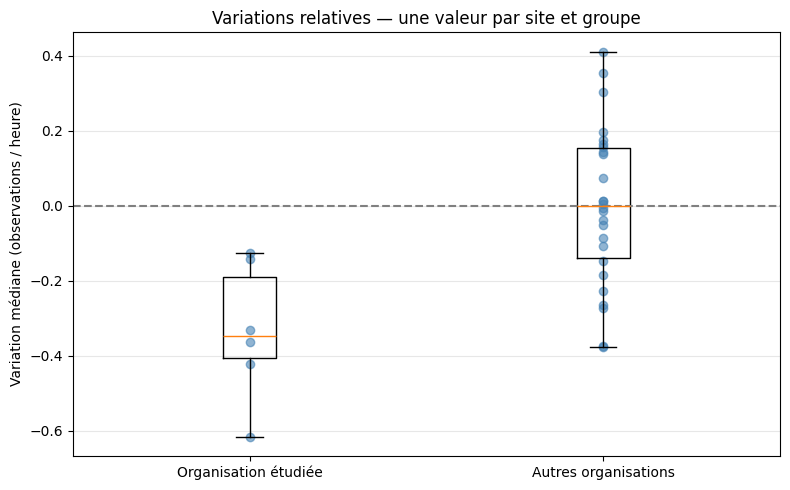

,nombre_sites,nombre_acces,variation_mediane
groupe,,,
Organisation étudiée,6,11,-0.347
Autres organisations,26,26,-0.000


In [47]:

organization_site_comparison = (
    eco_utils.compare_access_organizations_by_site(
        access_peer_comparison,
        "Horizon Field Research Cooperative"
    )
)

display(organization_site_comparison.round(3))

### Interprétation de l’analyse par site

Le contraste persiste lorsque chaque site contribue par une seule
valeur. Les six sites du groupe Horizon présentent une variation
relative médiane négative.

La différence observée ne semble donc pas dépendre uniquement
de la répétition des accès sur quelques sites.

Ce résultat ne démontre pas un effet causal. Nous examinons
maintenant les courbes autour d’un accès, pour observer les tendances
antérieures et les conditions techniques.

### 6.12. Examen détaillé d’un accès

Nous examinons le cas présentant la plus forte baisse relative.
Cette sélection sert à approfondir un cas et ne représente pas
l’ensemble des accès.

Sur une fenêtre de six mois avant et après l’intervention,
nous comparons le site à ses comparateurs pour l’activité,
la disponibilité et la qualité acoustique.

La date exacte de l’accès est indiquée pour distinguer les relevés
antérieurs et postérieurs à l’intervention.

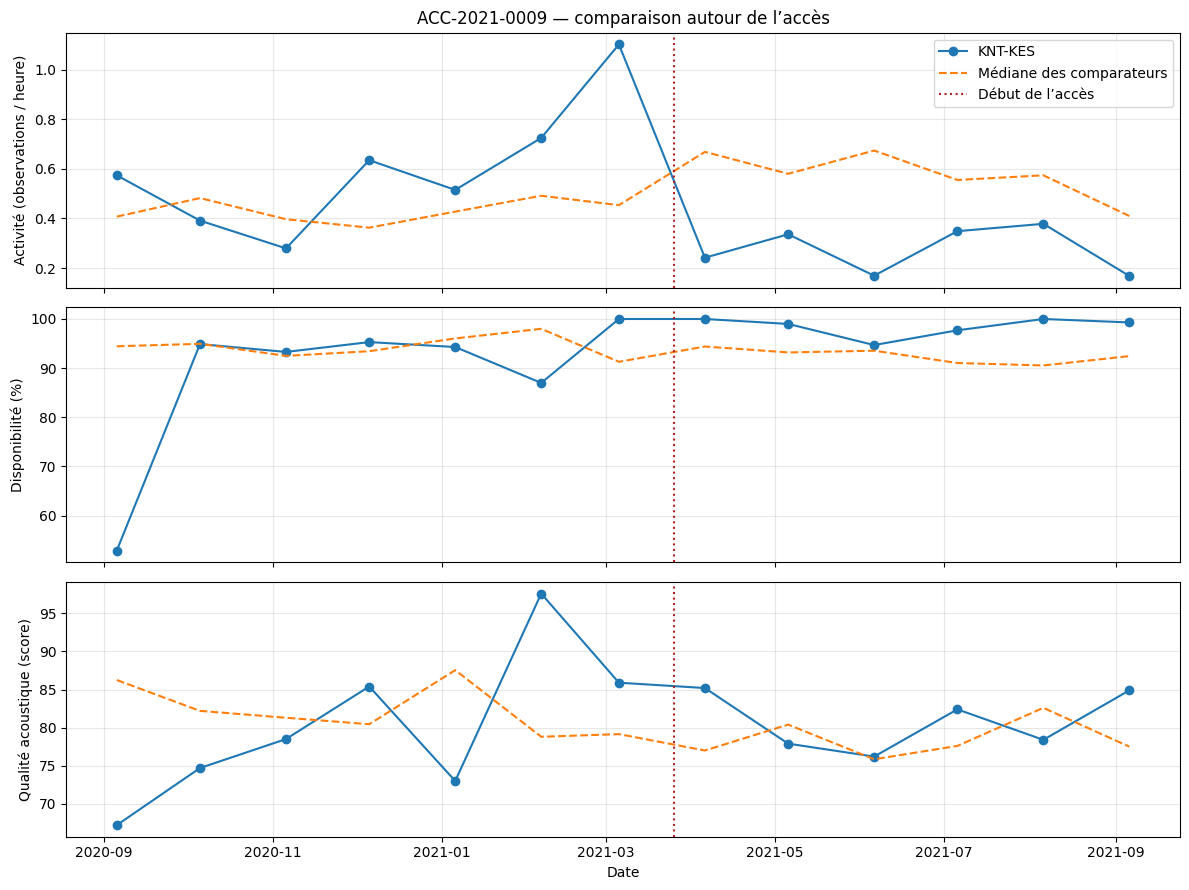

In [48]:

case_to_review = (
    access_peer_comparison
    .dropna(subset=["difference_relative"])
    .sort_values("difference_relative")
    .iloc[0]["access_case_number"]
)

eco_utils.plot_access_case_context(
    access_peer_comparison,
    access_comparators,
    bats_environment,
    case_to_review
)

### Interprétation du cas ACC-2021-0009

À KNT-KES, l’activité observée diminue entre les relevés de mars
et d’avril 2021, de part et d’autre de l’accès du 25 mars.
Elle reste ensuite inférieure à la médiane des comparateurs
sur la période représentée.

La disponibilité reste élevée après l’accès. La qualité acoustique
fluctue, mais ne présente pas de rupture simultanée comparable
à celle de l’activité. Ces indicateurs ne fournissent donc pas
d’explication technique évidente à la baisse.

Le relevé de mars est toutefois particulièrement élevé et les
évolutions antérieures du site et des comparateurs ne sont pas
parfaitement parallèles. Ce cas sélectionné pour sa forte baisse
ne permet donc pas, à lui seul, d’établir un effet de l’accès.

Nous examinons maintenant les conditions environnementales.

### 6.13. Conditions environnementales autour du cas étudié

Nous comparons la température, la pluie, les pesticides
et la perturbation de l’habitat aux mêmes dates sur KNT-KES
et ses sites comparateurs.

Nous recherchons des changements locaux susceptibles de contribuer
à la variation d’activité. Cette comparaison visuelle ne constitue
pas un ajustement simultané de tous les facteurs.

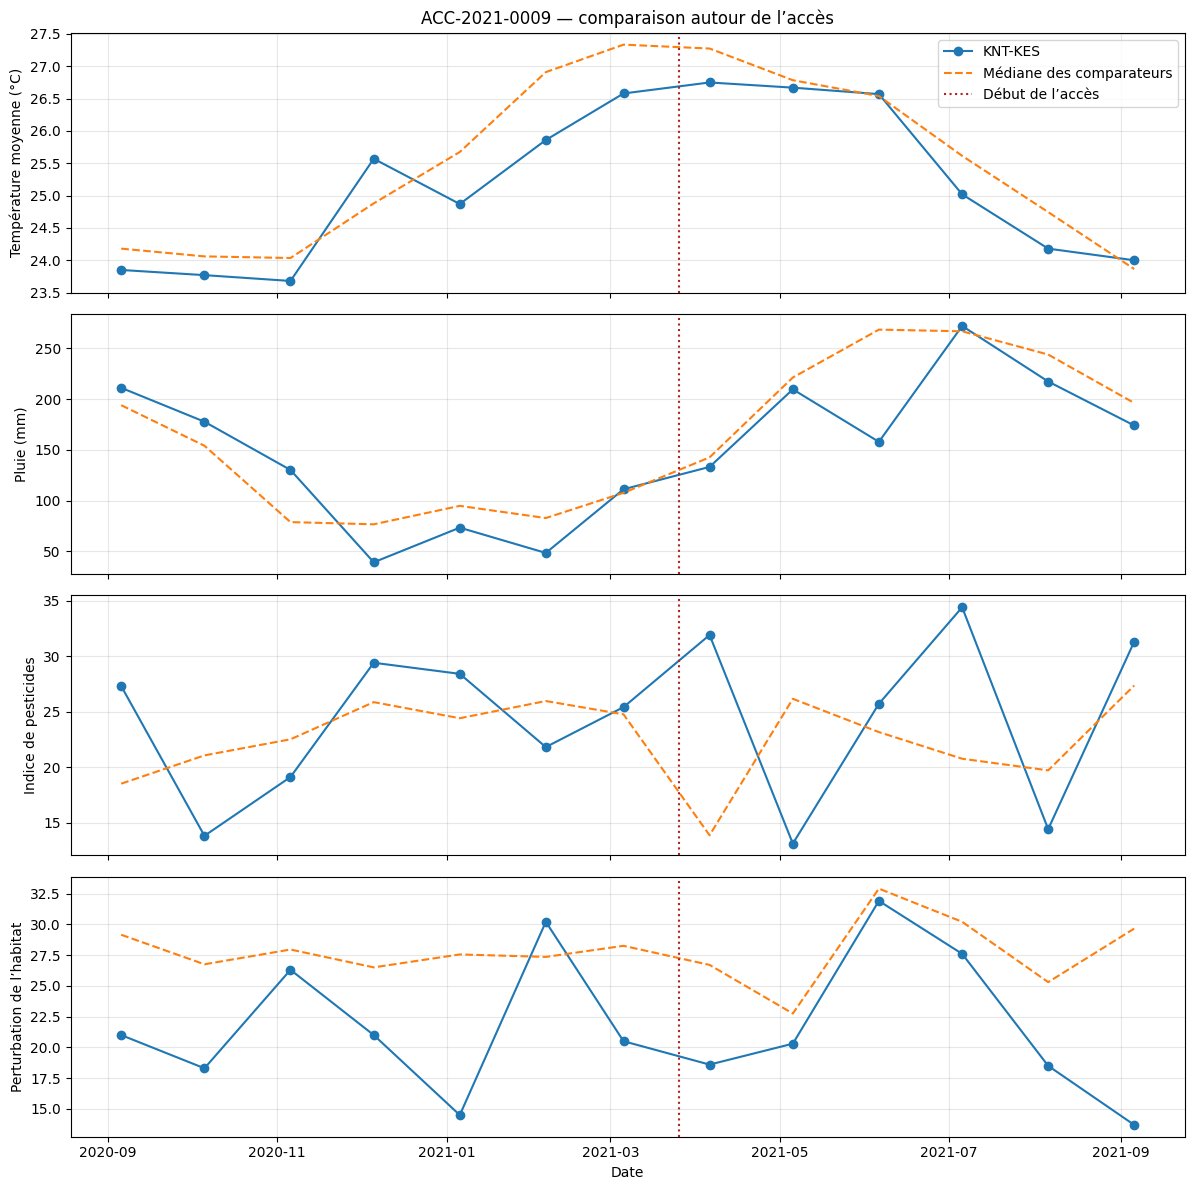

In [49]:

eco_utils.plot_access_case_context(
    access_peer_comparison,
    access_comparators,
    bats_environment,
    case_to_review,
    indicators={
        "mean_temperature_c": "Température moyenne (°C)",
        "rainfall_mm": "Pluie (mm)",
        "pesticide_index": "Indice de pesticides",
        "habitat_disturbance_index": "Perturbation de l’habitat"
    }
)

### Interprétation des conditions environnementales

La température suit une évolution globalement proche de celle
des comparateurs, sans rupture nette au moment de l’accès.
La pluie présente également un profil saisonnier similaire,
avec quelques différences mensuelles.

L’indice de pesticides augmente à KNT-KES en avril 2021,
alors qu’il diminue chez les comparateurs. Ce facteur pourrait
contribuer à la baisse d’activité et ne peut pas être écarté.
Son évolution devient ensuite irrégulière, tandis que l’activité
reste relativement faible.

La perturbation de l’habitat ne présente pas de hausse immédiate
après l’accès. Une augmentation apparaît en juin, également
visible chez les comparateurs.

Aucune explication unique n’est établie. L’association temporelle
avec l’accès reste une piste, mais les pesticides, les autres
conditions locales et la variabilité des relevés empêchent
une attribution causale.

### Bilan de l’étude des accès

Sur les 54 accès commencés, 39 disposent de trois mois de relevés
avant et après l’intervention. Le mois de l’accès a été exclu.

La prise en compte de la saisonnalité atténue la baisse globale.
Les résultats diffèrent toutefois selon les accès et les organisations.

Les accès d’Horizon présentent des variations plus négatives
que ceux des autres organisations. Ce contraste persiste après
comparaison avec des sites similaires et lorsque chaque site
contribue par une seule valeur.

La comparaison avec des sites similaires porte sur 37 accès.
Les deux accès sans comparateur restent des cas individuels.

L’examen détaillé de KNT-KES en mars 2021 montre une baisse
postérieure à l’accès, sans dégradation technique simultanée évidente.
Une variation des pesticides et un niveau d’activité élevé
juste avant l’accès limitent cependant l’interprétation.

Ces résultats identifient des situations à approfondir.
Ils ne démontrent ni un effet causal des accès ni la nature
des activités réalisées sur place.

## 7. Analyse textuelle et vérification des rapports de terrain

### Objectif

Nous analysons les 30 rapports de terrain pour repérer leurs thèmes,
leurs expressions caractéristiques et leurs ressemblances.

Nous utilisons les fréquences de mots et d’expressions, la méthode
TF-IDF et la similarité cosinus, présentées dans le cours de text mining.

Les résultats seront ensuite confrontés aux relevés et aux appareils
cités. Les textes constituent des sources à examiner, et leurs
affirmations ne sont pas considérées automatiquement comme vérifiées.

### 7.1. Chargement des rapports

Chaque document est identifié par `document_id`.
Nous conservons ses métadonnées et son texte original.

In [50]:
reports = pd.read_csv(
    data_path / "environmental_field_reports.csv",
    parse_dates=["document_date"]
)

print("Nombre de rapports :", len(reports))

display(
    reports[
        ["document_id", "site_code", "document_date", "title"]
    ].head()
)

Nombre de rapports : 30


,document_id,site_code,document_date,title
0,EFR-510088,KNT-KES,2024-04-02,Post-Access Ecological Incident at KNT-KES
1,EFR-510082,KNT-JAK,2019-04-01,Field Observation 27
2,EFR-510035,KNT-JQG,2022-09-08,Field Observation 28
3,EFR-510007,KNT-JQG,2025-02-15,Field Observation 29
4,EFR-510031,KNT-VLB,2020-07-22,Field Observation 30


### 7.2. Préparation des textes

Nous créons une copie du texte pour l’analyse lexicale :
passage en minuscules, retrait de la ponctuation et harmonisation
des espaces et des retours à la ligne.

Les textes originaux restent inchangés. Ils seront utilisés
pour interpréter les négations, les incertitudes et le contexte.

Les mots de liaison anglais seront filtrés lors de la vectorisation.

In [51]:
reports_text = eco_utils.prepare_report_texts(reports)

display(
    reports_text[
        ["document_id", "text_prepared"]
    ].head()
)

,document_id,text_prepared
0,EFR-510088,incident a post access inspection was conducte...
1,EFR-510082,site and time field observation at during sens...
2,EFR-510035,site and time field observation at during habi...
3,EFR-510007,site and time field observation at during rain...
4,EFR-510031,site and time field observation at during frui...


### 7.3. Vocabulaire et expressions fréquentes

Nous représentons les mots et les groupes de deux mots consécutifs
les plus présents dans les rapports.

Les mots de liaison anglais sont écartés des résultats.
Chaque terme est compté une seule fois par rapport.

Cette analyse décrit le vocabulaire commun du corpus. Une expression
fréquente peut provenir d’un modèle de rédaction partagé et ne
constitue pas, à elle seule, un indice d’événement particulier.

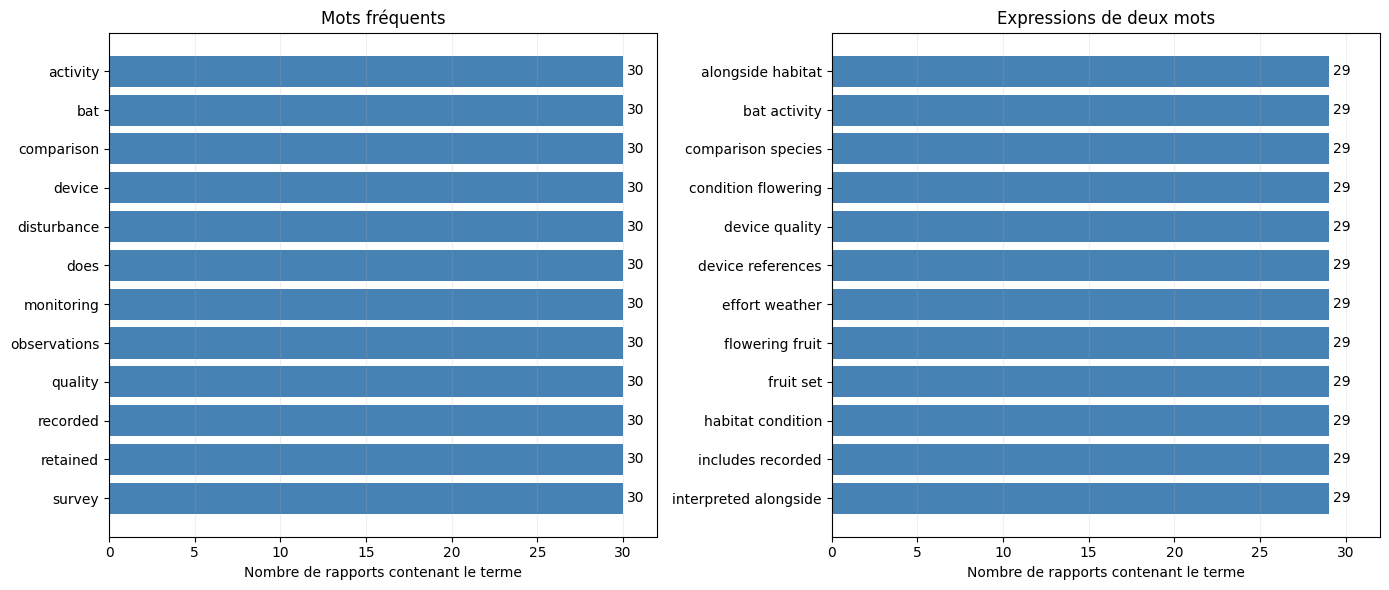

In [52]:

frequent_report_terms = eco_utils.plot_frequent_report_terms(
    reports_text
)

### 7.4. Termes caractéristiques avec TF-IDF

Les fréquences ont révélé un vocabulaire largement partagé.
Nous utilisons TF-IDF pour identifier les termes qui distinguent
chaque rapport du reste du corpus.

Nous analysons les mots et les groupes de deux mots après filtrage
des mots de liaison anglais. Les termes présents dans plus de 90 %
des rapports sont écartés pour limiter les formulations communes.

Les cinq termes les mieux pondérés sont présentés pour chaque
document. Leur poids indique une spécificité lexicale,
pas la véracité des affirmations.

In [53]:
reports_text = eco_utils.prepare_report_texts(reports)

report_tfidf, report_vectorizer, report_keywords = (
    eco_utils.extract_report_tfidf(reports_text)
)

with pd.option_context("display.max_colwidth", 150):
    display(report_keywords)

,document_id,title,termes_caracteristiques
0,EFR-510088,Post-Access Ecological Incident at KNT-KES,"conducted, cut, post, post access, material"
1,EFR-510082,Field Observation 27,"cycle, sensor maintenance, sensor, maintenance cycle, cycle includes"
2,EFR-510035,Field Observation 28,"assessment, disturbance assessment, assessment includes, concerns habitat, assessment method"
3,EFR-510007,Field Observation 29,"exception, exception review, rainfall exception, concerns rainfall, review"
4,EFR-510031,Field Observation 30,"set monitoring, concerns fruit, monitoring includes, observation fruit, monitoring method"
5,EFR-510020,Field Observation 31,"access path, path inspection, inspection, inspection includes, concerns access"
6,EFR-510048,Field Observation 32,"bat monitoring, seasonal bat, concerns seasonal, monitoring includes, observation seasonal"
7,EFR-510026,Monthly Monitoring Report 33,"pollination, pollination survey, orchard pollination, survey includes, concerns orchard"
8,EFR-510037,Monthly Monitoring Report 34,"cave microclimate, cave, microclimate, microclimate review, concerns cave"
9,EFR-510054,Monthly Monitoring Report 35,"cycle, sensor, sensor maintenance, maintenance cycle, cycle includes"


### Interprétation des termes caractéristiques

Après retrait des identifiants, les termes caractéristiques
font ressortir plusieurs sujets récurrents : maintenance des capteurs,
perturbation de l’habitat, pluie, fructification, chemins d’accès,
pollinisation et microclimat.

Ces sujets apparaissent dans des documents portant des titres
différents. Le titre ne suffit donc pas à résumer leur contenu.

EFR-510088 présente un vocabulaire distinct, notamment autour
de l’après-accès et du matériel coupé. Cette spécificité lexicale
justifie une lecture détaillée, sans valider les affirmations du rapport.

### 7.5. Similarité entre les rapports

Nous calculons la similarité cosinus entre les vecteurs TF-IDF.

Une valeur proche de 1 indique un vocabulaire pondéré très similaire.
Une valeur proche de 0 indique peu de vocabulaire pondéré partagé.
La diagonale vaut 1, car chaque rapport est comparé à lui-même.

La carte permet de repérer des groupes de textes proches.
Une forte similarité peut refléter un thème ou un modèle de rédaction
commun ; elle ne constitue pas une corroboration indépendante
des événements rapportés.

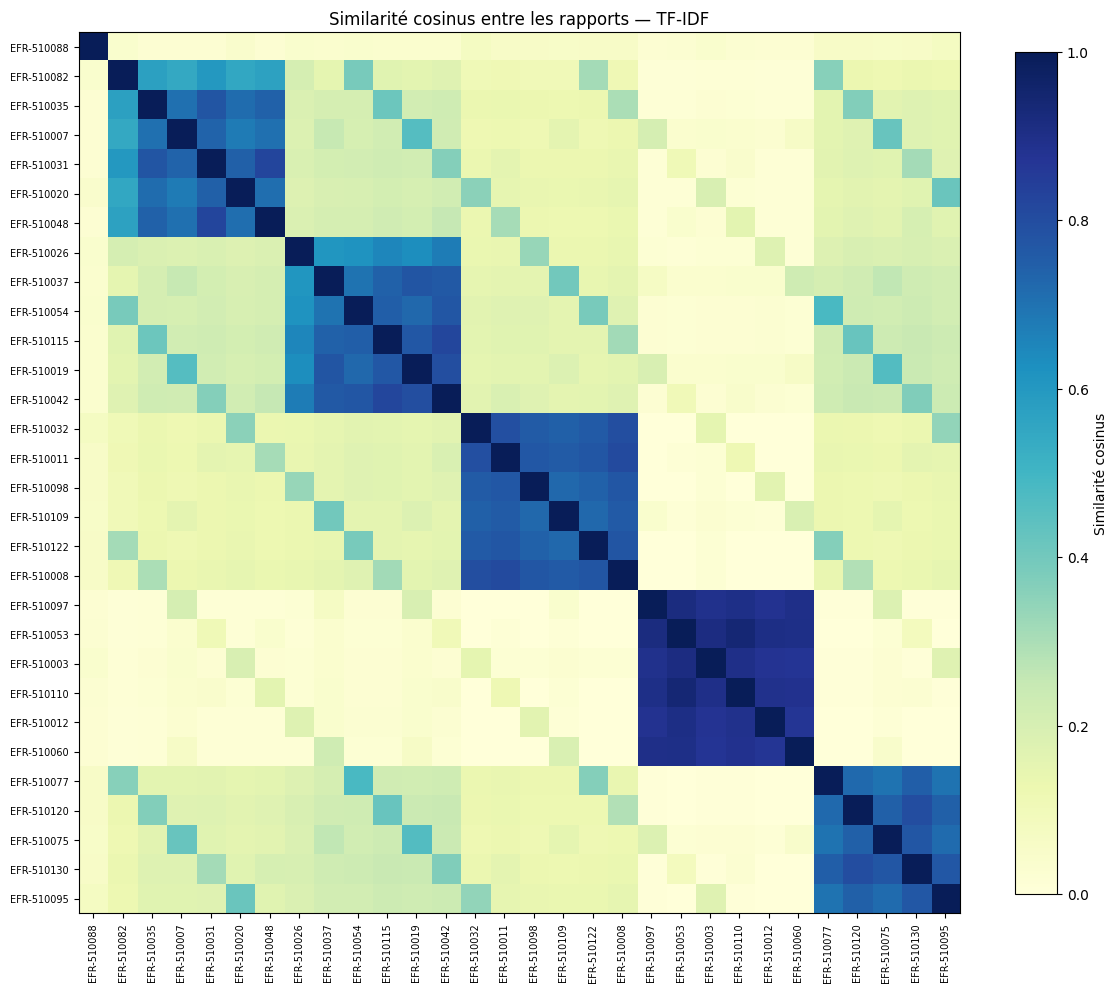

In [54]:
report_similarity = eco_utils.plot_report_similarity(
    reports_text,
    report_tfidf
)

### Lecture de la carte de similarité

La carte représente les similarités cosinus entre les vecteurs
TF-IDF des 30 rapports.

Plusieurs blocs de forte similarité apparaissent. Ils suggèrent
des ensembles partageant un vocabulaire ou des formulations,
sans établir qu’ils décrivent les mêmes événements.

EFR-510088 se distingue par une faible similarité avec les autres
rapports. Cette particularité lexicale motive son examen détaillé,
mais ne permet pas de valider ses affirmations.

### 7.6. Confrontation des rapports aux données citées

Pour chaque rapport, nous retrouvons l’enquête mentionnée
et le fonctionnement de l’appareil pendant le mois de cette enquête.

Nous comparons les sites et les dates, puis relevons
la disponibilité et la qualité acoustique enregistrées.

Un rapport antérieur à l’enquête citée constitue un décalage
à examiner. Nous ne modifions pas automatiquement les références
ou les dates pour les faire concorder.

In [55]:
report_reference_comparison = eco_utils.compare_report_references(
    reports,
    bats,
    operations
)

display(
    report_reference_comparison[
        [
            "document_id",
            "site_code",
            "document_date",
            "survey_start",
            "enquete_retrouvee",
            "meme_site",
            "rapport_avant_releve",
            "appareil_mois_retrouve",
            "uptime_pct",
            "acoustic_quality",
            "fault_code"
        ]
    ]
)

,document_id,site_code,document_date,survey_start,enquete_retrouvee,meme_site,rapport_avant_releve,appareil_mois_retrouve,uptime_pct,acoustic_quality,fault_code
0,EFR-510088,KNT-KES,2024-04-02,2024-04-05 18:00:00,True,True,True,True,83.1,73.1,NO_FAULT
1,EFR-510082,KNT-JAK,2019-04-01,2024-04-05 18:00:00,True,True,True,True,100.0,85.3,NO_FAULT
2,EFR-510035,KNT-JQG,2022-09-08,2020-11-05 18:00:00,True,True,False,True,91.3,85.5,NO_FAULT
3,EFR-510007,KNT-JQG,2025-02-15,2023-12-05 18:00:00,True,True,False,True,98.6,69.6,NO_FAULT
4,EFR-510031,KNT-VLB,2020-07-22,2020-07-05 18:00:00,True,True,False,True,90.9,92.8,NO_FAULT
5,EFR-510020,KNT-VLB,2023-12-02,2023-08-05 18:00:00,True,True,False,True,86.7,85.6,NO_FAULT
6,EFR-510048,KNT-CHP,2018-05-09,2020-03-05 18:00:00,True,True,True,True,33.6,64.9,MICROPHONE_DRIFT
7,EFR-510026,KNT-CHP,2021-10-16,2023-04-05 18:00:00,True,True,True,True,49.3,63.6,MICROPHONE_DRIFT
8,EFR-510037,KNT-YRG,2024-03-23,2019-11-05 18:00:00,True,True,False,True,95.5,81.1,NO_FAULT
9,EFR-510054,KNT-YRG,2019-08-03,2022-12-05 18:00:00,True,True,True,True,100.0,78.5,NO_FAULT


### Interprétation de la confrontation des références

Les 30 rapports renvoient à des enquêtes existantes du même site.
L’appareil cité est également retrouvé pour le mois de chaque enquête.

Cependant, 15 rapports sont datés avant le début de l’enquête
mentionnée. Ces décalages chronologiques nécessitent une lecture
du contenu et limitent l’utilisation des rapports comme preuves.

Une référence correcte sur le plan des identifiants ne garantit donc
pas la concordance temporelle ni l’exactitude des affirmations.

Nous conservons les références et les dates originales.
Les incohérences sont documentées, sans correction supposée.

### 7.7. Lecture des rapports présentant un décalage chronologique

Quinze rapports sont datés avant le début de l’enquête citée.

Nous lisons leur contenu pour déterminer si cette enquête est
annoncée comme future ou présentée comme déjà réalisée.
Nous relevons aussi les indications temporelles et les références
susceptibles d’éclairer le décalage.

Aucune date ni référence n’est corrigée automatiquement.

In [56]:
review_ids = report_reference_comparison.loc[
    report_reference_comparison["rapport_avant_releve"].eq(True),
    "document_id"
].tolist()

for document_id in review_ids:
    eco_utils.show_field_report(reports, document_id)
    print("\n" + "—" * 60 + "\n")

Document : EFR-510088
Titre : Post-Access Ecological Incident at KNT-KES
Site : KNT-KES
Date : 2024-04-02 00:00:00
Auteur : Anika Dren
Organisation : Horizon Field Research Cooperative
Enquête citée : BAT-0000064
Appareil cité : DEV-KNTKES-2

Texte du rapport :

INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entr

### Synthèse des quinze rapports présentant un décalage chronologique

Les quinze rapports sont antérieurs à l’enquête indiquée dans leurs
métadonnées. Aucun texte n’explique explicitement ce décalage
par une enquête annoncée comme future.

Certains textes présentent directement l’enquête comme déjà
examinée. Dans d’autres, la référence figure seulement dans
les métadonnées : le rattachement temporel reste alors non expliqué.

| Rapport | Contenu principal | Conclusion de la lecture |
|---|---|---|
| EFR-510088 | Baisse après accès et traces physiques compatibles avec une manipulation d’animaux. | Les observations sont présentées comme réalisées. Le décalage persiste. La disponibilité annoncée supérieure à 90 % ne concorde pas avec les 83,1 % du mois associé, sous réserve d’une différence de période. |
| EFR-510082 | Suivi de terrain et capture présentée comme autorisée, suivie d’un relâcher. | L’enquête est présentée comme déjà examinée. Le décalage persiste. Le texte apporte une explication ordinaire possible aux manipulations d’animaux. |
| EFR-510048 | Suivi saisonnier avec limitations liées au vent et au bruit. | L’enquête est présentée comme déjà examinée. Le décalage persiste. Aucune attribution à un prélèvement organisé n’est établie. |
| EFR-510026 | Analyse saisonnière et couverture technique jugée suffisante. | L’enquête est présentée comme déjà utilisée. Le décalage persiste. L’appréciation technique doit être nuancée par la disponibilité de 49,3 % et la dérive de microphone du mois associé. |
| EFR-510054 | Variations interprétées par la saisonnalité, la pluie et la floraison. | L’enquête est présentée comme déjà utilisée. Le décalage persiste et limite la confrontation temporelle. |
| EFR-510011 | Visite de routine, appareil en place et perturbation mineure des sédiments attribuée à la maintenance. | Aucun passage ne justifie le rattachement à une enquête postérieure. Les observations sont présentées comme celles d’une visite réalisée. |
| EFR-510098 | Visite de routine et perturbation mineure attribuée à la maintenance. | Le lien temporel avec l’enquête indiquée dans les métadonnées n’est pas expliqué. |
| EFR-510109 | Visite de routine consacrée au microclimat. | Le lien temporel avec l’enquête indiquée dans les métadonnées n’est pas expliqué. |
| EFR-510122 | Visite de routine consacrée à la maintenance des capteurs. | Le lien temporel avec l’enquête indiquée dans les métadonnées n’est pas expliqué. |
| EFR-510008 | Visite de routine consacrée aux perturbations de l’habitat. | Le lien temporel avec l’enquête indiquée dans les métadonnées n’est pas expliqué. |
| EFR-510053 | Réduction temporaire de qualité acoustique pouvant diminuer la sensibilité de détection. | Le fonctionnement est décrit comme déjà observé. La période précise et son lien avec l’enquête postérieure restent à clarifier. |
| EFR-510110 | Réduction temporaire de qualité acoustique et recommandations de maintenance. | Le fonctionnement est décrit comme déjà observé. La période précise et son lien avec l’enquête postérieure restent à clarifier. |
| EFR-510077 | Baisse temporaire attribuée principalement à la pluie, au bruit et à un masquage temporaire de l’appareil. | L’enquête est présentée comme ayant déjà montré une baisse. Le décalage persiste. Des explications ordinaires sont proposées. |
| EFR-510120 | Baisse temporaire avec pluie, bruit et masquage de l’appareil. | L’enquête est présentée comme ayant déjà montré une baisse. Le décalage persiste. Ces explications restent à confronter aux mesures. |
| EFR-510130 | Baisse temporaire et perturbations météorologiques ou techniques. | L’enquête est présentée comme ayant déjà montré une baisse. Le décalage persiste. Aucun prélèvement organisé n’est établi. |

### Bilan de la lecture

Les incohérences chronologiques ne sont pas résolues par les textes.
Elles limitent l’utilisation de ces documents comme preuves datées,
sans démontrer que leur contenu est entièrement faux.

Les rapports proposent plusieurs explications ordinaires :
saisonnalité, météo, maintenance, perturbation temporaire
et capture présentée comme autorisée.

EFR-510088 se distingue par des traces physiques rapportées
et une hypothèse de manipulation ou de prélèvement.
Le texte conserve toutefois d’autres explications et n’identifie
ni responsable ni finalité.

Les formulations répétées ne constituent pas des confirmations
indépendantes. Les conclusions doivent rester fondées sur
la confrontation des sources et des mesures.

In [57]:
remaining_ids = reports.loc[
    ~reports["document_id"].isin(review_ids),
    "document_id"
]

for document_id in remaining_ids:
    eco_utils.show_field_report(reports, document_id)
    print("\n" + "—" * 60 + "\n")

Document : EFR-510035
Titre : Field Observation 28
Site : KNT-JQG
Date : 2022-09-08 00:00:00
Auteur : Uma Wessen
Organisation : Horizon Field Research Cooperative
Enquête citée : BAT-0001037
Appareil cité : DEV-KNTJQG-1

Texte du rapport :

SITE AND TIME
Field observation at KNT-JQG during habitat disturbance assessment.

METHOD
The team completed a standard dusk transect and reviewed survey BAT-0001037. Effort and weather were recorded.

OBSERVATIONS
Bat activity and comparison-species counts varied across the interval. Vegetation and access conditions showed no acute change.

LIMITATIONS
Wind and intermittent background noise reduced certainty in part of the survey.

The reporting interval concerns habitat disturbance assessment and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references 

### Lecture des quinze rapports sans antériorité à l’enquête citée

| Rapport | Contenu principal | Conclusion de la lecture |
|---|---|---|
| EFR-510035 | Suivi de l’habitat, variations de comptage, limitations liées au vent et au bruit. | Plusieurs explications sont proposées, sans attribution à un prélèvement organisé. |
| EFR-510007 | Suivi concernant les conditions de pluie, avec limitations d’observation. | Les observations restent générales et doivent être confrontées aux mesures. |
| EFR-510031 | Suivi de la fructification et variations d’activité. | Le texte ne démontre pas de mécanisme causal entre activité et production. |
| EFR-510020 | Inspection des chemins d’accès et observations de terrain. | Aucun changement aigu n’est rapporté, sans démonstration de l’absence de perturbation. |
| EFR-510037 | Analyse du microclimat, de la saisonnalité et des sites voisins. | Une évolution ordinaire est proposée ; la comparaison annoncée reste à vérifier. |
| EFR-510115 | Analyse des perturbations de l’habitat et de la saisonnalité. | Le texte ne considère pas la période comme uniquement anormale. Cette appréciation reste à confronter aux données. |
| EFR-510019 | Analyse des conditions de pluie et des variations saisonnières. | La couverture technique est jugée suffisante, sans critère explicite permettant de valider cette appréciation. |
| EFR-510042 | Suivi de la fructification et comparaison avec les sites voisins. | Les conclusions sont générales et ne fournissent pas de résultats chiffrés détaillés. |
| EFR-510032 | Visite de routine et perturbation mineure attribuée à la maintenance. | Une explication ordinaire est proposée pour les traces observées. |
| EFR-510097 | Baisse temporaire de qualité acoustique pouvant diminuer la détection. | Le texte souligne une limite technique ponctuelle que les moyennes mensuelles peuvent masquer. |
| EFR-510003 | Difficultés acoustiques temporaires et recommandations de maintenance. | Les problèmes sont rapportés, mais leur durée et leur effet sur les comptages ne sont pas quantifiés. |
| EFR-510012 | Difficultés acoustiques temporaires ; auteur non renseigné. | L’absence d’auteur limite la traçabilité, sans démontrer que le contenu est faux. |
| EFR-510060 | Difficultés acoustiques temporaires et comparaison recommandée avec une station de secours. | Le résultat de cette comparaison n’est pas fourni dans le texte. |
| EFR-510075 | Baisse temporaire attribuée à la pluie, au bruit et à un masquage de l’appareil. | Des explications ordinaires sont proposées et restent à vérifier dans les relevés. |
| EFR-510095 | Baisse temporaire avec perturbations météorologiques et techniques. | Le rapport privilégie une perturbation temporaire, sans exclure un déplacement saisonnier. |

### Bilan de la lecture et du text mining

Les fréquences, les termes TF-IDF et les similarités cosinus
mettent en évidence des formulations largement standardisées.
Les ressemblances textuelles ne constituent donc pas
des confirmations indépendantes des événements.

La lecture montre que la majorité des rapports propose plusieurs
explications ordinaires aux variations : météo, saisonnalité,
maintenance, déplacement des animaux et perturbations temporaires.

Les mentions de capture ou de manipulation doivent être interprétées
en contexte : certains textes décrivent des captures présentées
comme autorisées et suivies d’un relâcher.

EFR-510088 se distingue par des traces physiques rapportées
et une hypothèse de manipulation ou de prélèvement après accès.
Il ne précise cependant ni responsable ni finalité et présente
des discordances documentaires à clarifier.

Les références des 30 rapports existent et correspondent au site
indiqué. Toutefois, 15 documents précèdent l’enquête citée.
Pour les autres, une chronologie possible ne garantit pas
la concordance de la période décrite ni l’exactitude des affirmations.

Ces documents apportent donc du contexte et des hypothèses,
mais ne permettent pas de démontrer un prélèvement clandestin.

### 7.8. Mise en contexte des mesures citées

Pour chaque rapport, nous examinons l’activité et la pluie
pendant le mois de l’enquête citée.

Nous les comparons à la médiane du même mois de l’année
sur le même site, en excluant l’enquête étudiée.

Cette référence permet de situer les observations par rapport
aux autres années. Une activité inférieure à cette référence
ne démontre pas un prélèvement.

Les mesures mensuelles ne permettent pas de confirmer directement
un épisode de pluie ou un problème technique de quelques heures.
Les décalages chronologiques des rapports restent également présents.

In [58]:

report_measurements = eco_utils.summarize_report_measurements(
    reports,
    bats_environment
)

with pd.option_context("display.max_rows", 30):
    display(report_measurements.round(3))

,document_id,site_code,mois_enquete,activite_observee,activite_reference,ecart_activite,pluie_mm,pluie_reference_mm,ecart_pluie_mm
0,EFR-510088,KNT-KES,2024-04,0.334,0.745,-0.410,140.6,151.00,-10.40
1,EFR-510082,KNT-JAK,2024-04,0.813,0.683,0.130,164.7,142.20,22.50
2,EFR-510035,KNT-JQG,2020-11,0.312,0.179,0.133,107.7,124.00,-16.30
3,EFR-510007,KNT-JQG,2023-12,0.246,0.285,-0.039,76.6,112.40,-35.80
4,EFR-510031,KNT-VLB,2020-07,0.193,0.650,-0.457,224.4,243.60,-19.20
5,EFR-510020,KNT-VLB,2023-08,0.209,0.375,-0.166,185.7,187.00,-1.30
6,EFR-510048,KNT-CHP,2020-03,0.932,0.692,0.239,83.9,100.05,-16.15
7,EFR-510026,KNT-CHP,2023-04,1.083,0.821,0.262,126.2,154.95,-28.75
8,EFR-510037,KNT-YRG,2019-11,0.086,0.129,-0.043,130.4,142.90,-12.50
9,EFR-510054,KNT-YRG,2022-12,0.037,0.198,-0.162,106.9,107.20,-0.30


### Interprétation de la confrontation aux mesures

L’enquête citée par EFR-510088 présente une activité inférieure
à la référence saisonnière de KNT-KES. Cette observation concorde
avec l’affirmation d’une activité faible, sans valider les traces
physiques rapportées ni l’hypothèse de prélèvement.

Les cinq rapports d’incident proposant des explications ordinaires
correspondent également à une activité inférieure à leur référence.
Une activité faible ne permet donc pas de distinguer, à elle seule,
un incident ordinaire d’un prélèvement supposé.

Les explications météorologiques ne sont que partiellement
documentées par les mesures disponibles. Une pluie mensuelle
supérieure à la référence ne démontre pas un épisode intense
pendant le relevé ; une valeur inférieure ne l’exclut pas.

Les incohérences chronologiques et les différences d’échelle
temporelle restent des limites à la confrontation des sources.

In [59]:
raw_environment = pd.read_csv(
    PROJECT_ROOT / "data" / "ecology" / "environmental_monthly.csv"
)

raw_environment["reporting_month"] = pd.to_datetime(
    raw_environment["reporting_month"],
    format="mixed",
    errors="raise"
)

display(
    raw_environment.loc[
        raw_environment["site_code"].eq("KNT-BME")
        & raw_environment["reporting_month"].eq(
            pd.Timestamp("2023-01-01")
        ),
        [
            "site_code",
            "reporting_month",
            "rainfall_mm",
            "pesticide_index",
            "vegetation_cover_pct"
        ]
    ]
)

,site_code,reporting_month,rainfall_mm,pesticide_index,vegetation_cover_pct
1998,KNT-BME,2023-01-01,52.5,52.7,NaN


In [60]:
mask = report_measurements["document_id"].eq("EFR-510130")

report_measurements.loc[mask, "pluie_mm"] = 52.5

report_measurements.loc[mask, "ecart_pluie_mm"] = (
    report_measurements.loc[mask, "pluie_mm"]
    - report_measurements.loc[mask, "pluie_reference_mm"]
)

### Complément depuis les données brutes

Pour EFR-510130, la pluie était absente de la table de rapprochement
parce que le mois avait été supprimé lors du nettoyage pour
une valeur manquante de couverture végétale.

Le fichier brut contient une pluie de 52,5 mm, contre une référence
saisonnière de 75,1 mm, soit un écart de −22,6 mm.

La mesure mensuelle ne soutient pas une pluie inhabituellement élevée
à cette échelle. Elle ne permet cependant pas d’exclure un épisode
intense pendant le relevé.

Ce cas montre qu’une observation incomplète peut conserver
des informations utiles pour certaines analyses.

### 7.9. Bilan de l’analyse des rapports de terrain

L’analyse porte sur les 30 rapports, combinant fréquences lexicales,
TF-IDF, similarité cosinus, lecture contextualisée et confrontation
aux données citées.

Les textes présentent des formulations largement standardisées.
Leur ressemblance ne constitue donc pas une confirmation indépendante
des événements décrits.

Les enquêtes et appareils cités sont retrouvés sur les sites indiqués.
Cependant, 15 rapports précèdent l’enquête mentionnée.
Leur contenu n’explique pas ces décalages. Les autres rapports
présentent une chronologie possible, sans être automatiquement fiables.

Plusieurs rapports décrivant une baisse correspondent à une activité
inférieure à la référence saisonnière. Cette concordance ne démontre
pas les causes proposées dans les textes.

Les explications par de fortes pluies ne sont pas systématiquement
soutenues par les cumuls mensuels. Ces mesures ne permettent toutefois
pas de confirmer ou d’exclure un épisode intense de courte durée.

EFR-510088 apporte une hypothèse de manipulation ou de prélèvement
après accès à KNT-KES. L’activité faible est observable dans les relevés,
mais les traces physiques restent uniquement rapportées par le texte.
Les discordances de date et de disponibilité limitent sa valeur
comme preuve.

D’autres documents proposent des explications ordinaires :
maintenance, météo, déplacement saisonnier ou capture présentée
comme autorisée et suivie d’un relâcher.

Enfin, le retour aux données brutes a permis de retrouver une mesure
de pluie perdue lors de la suppression d’un mois incomplet.
Une absence dans la table préparée ne signifie donc pas toujours
une absence dans la source.

Les rapports apportent du contexte et des hypothèses à transmettre
aux autres domaines du projet. Ils ne permettent pas, à eux seuls,
de démontrer un prélèvement clandestin, d’identifier un responsable
ou d’établir une finalité.

## 8. Synthèse générale de l’analyse écologique

### 8.1. Principaux résultats

Le suivi comprend 64 sites disposant chacun de 78 relevés mensuels,
de janvier 2019 à juin 2025. Les régions présentent des compositions
différentes en habitats et en types de suivi.

L’activité observée des chauves-souris varie selon les saisons
et les sites. Les observations par heure permettent de tenir compte
des différences de durée de suivi, sans corriger toutes les conditions
de détection.

| Axe étudié | Résultat principal | Limite |
|---|---|---|
| Saisonnalité | L’activité globale est généralement plus élevée au printemps et plus faible vers septembre–octobre. | Le profil global peut masquer des évolutions locales. |
| Environnement | Une partie des associations avec la température disparaît après retrait du profil saisonnier moyen. Les associations avec les pesticides et la perturbation de l’habitat restent généralement négatives. | Les effets propres des facteurs ne sont pas isolés. |
| Capteurs | Les corrélations techniques sont généralement proches de zéro sur les 64 sites. Les pannes déclarées correspondent toutefois à des conditions techniques dégradées. | Une faible corrélation globale n’exclut pas un biais ponctuel. |
| Maintenance | Les quatre prestataires suivent chacun 16 sites. AVL-TRP et KNT-CHP présentent particulièrement beaucoup de pannes déclarées. | Aucun site ne change de prestataire : leurs effets ne peuvent pas être séparés simplement. |
| Vergers | L’activité est positivement associée à la fructification et au rendement. Les associations diminuent après retrait du profil saisonnier moyen. | La contribution causale des chauves-souris n’est pas quantifiée. |
| Accès | Les accès d’Horizon présentent des variations plus négatives, y compris relativement à des sites similaires. | Les interventions ne sont pas attribuées aléatoirement et plusieurs facteurs restent possibles. |
| Rapports | Les textes apportent des hypothèses et des explications alternatives. Quinze présentent un décalage chronologique. | Leurs affirmations ne constituent pas automatiquement des faits vérifiés. |

### 8.2. Résultat central concernant les accès

Parmi les 39 accès disposant d’une fenêtre complète de trois mois
avant et après, ceux demandés par Horizon présentent des variations
plus négatives que ceux des autres organisations.

La comparaison avec des sites similaires porte sur 37 accès.
La variation relative médiane atteint −0,364 observation par heure
pour les 11 accès d’Horizon concernés, contre une valeur proche
de zéro pour les 26 autres accès.

Le contraste reste visible lorsque chaque site contribue
par une seule valeur. Il ne semble donc pas dépendre uniquement
de la répétition des accès sur certains sites.

Ce résultat identifie une association à approfondir. Il ne démontre
pas que l’organisation provoque les baisses ni ne précise
les activités réellement réalisées sur place.

### 8.3. Apport et limites des rapports

EFR-510088 rapporte des traces physiques compatibles avec
une manipulation d’animaux après un accès à KNT-KES en 2024.

Cette description rejoint une piste issue des mesures, mais
les traces ne sont pas directement vérifiables dans les fichiers.
Le rapport présente également des discordances de date
et de disponibilité à clarifier.

Les autres textes rappellent que des variations peuvent provenir
de la météo, de la maintenance, de déplacements saisonniers
ou de captures présentées comme autorisées.

Les documents doivent donc être utilisés comme des sources
contextuelles, en conservant leurs contradictions et leurs limites.

### 8.4. Conclusion écologique

L’analyse met en évidence des baisses d’activité associées
à certains accès, particulièrement dans le groupe Horizon.
Ces baisses ne se résument pas au profil saisonnier moyen
ni à l’évolution des sites comparables.

Les conditions techniques et environnementales restent néanmoins
des explications possibles pour certains cas. Les données disponibles
ne permettent pas d’établir une cause unique.

La piste principale à transmettre au groupe concerne donc
les interventions associées à ces baisses : leurs autorisations,
leurs acteurs et leurs éventuels liens avec les opérations logistiques.

### 8.5. Pistes à croiser avec les autres domaines

- Examiner les dossiers ACC-2021-0009 et ACC-2024-0014 à KNT-KES.
- Rechercher les acteurs et les autorisations associés aux accès
  présentant les baisses les plus importantes.
- Examiner d’éventuels mouvements logistiques proches de ces accès,
  sans assimiler une proximité temporelle à une preuve de transport.
- Conserver EFR-510088 comme source à confronter, avec ses discordances.
- Garder les cas ordinaires et les contre-exemples dans la synthèse.

## 9.Livrables


In [61]:
from pathlib import Path
from unittest.mock import patch
import matplotlib.pyplot as plt

# Dossiers de sortie
export_path = PROJECT_ROOT / "exports" / "ecologie"
tables_path = export_path / "tableaux"
figures_path = export_path / "figures"

tables_path.mkdir(parents=True, exist_ok=True)
figures_path.mkdir(parents=True, exist_ok=True)


# 1. Export des tableaux, sans arrondir les valeurs
tables = {
    "groupes_sites": site_groups,
    "profils_sites": site_activity,
    "indicateurs_capteurs": provider_site_summary,
    "comparaison_acces": access_peer_comparison,
    "references_rapports": report_reference_comparison,
    "mesures_rapports": report_measurements
}

for name, table in tables.items():
    table.to_csv(
        tables_path / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )


# 2. Enregistrer les figures sans modifier les fonctions existantes
def export_plot(filename, function, *args, **kwargs):
    def save_figure(*show_args, **show_kwargs):
        figure = plt.gcf()
        figure.savefig(
            figures_path / filename,
            dpi=300,
            bbox_inches="tight"
        )
        plt.close(figure)

    with patch("matplotlib.pyplot.show", side_effect=save_figure):
        function(*args, **kwargs)


export_plot(
    "01_evolution_globale.png",
    eco_utils.plot_monthly_bat_activity,
    bats
)

export_plot(
    "02_evolution_regions.png",
    eco_utils.plot_bat_activity_by_region,
    bats,
    sites
)

export_plot(
    "03_pannes_capteurs.png",
    eco_utils.compare_declared_faults,
    bats_devices
)

export_plot(
    "04_vergers.png",
    eco_utils.plot_orchard_relationships,
    orchard_analysis
)

export_plot(
    "05_variations_acces.png",
    eco_utils.compare_access_organization,
    access_peer_comparison,
    "Horizon Field Research Cooperative",
    value_column="difference_relative",
    title="Variations relatives aux sites comparables"
)

export_plot(
    "06_cas_KNT_KES_2021.png",
    eco_utils.plot_access_case_context,
    access_peer_comparison,
    access_comparators,
    bats_environment,
    "ACC-2021-0009"
)

print("Export terminé : 6 tableaux et 6 graphiques.")
print("Dossier :", export_path.resolve())

Export terminé : 6 tableaux et 6 graphiques.
Dossier : C:\Users\Lenovo\Desktop\Data Mining\20262027-UE-DataMining-Project\exports\ecologie
